# Session 3: the Norway sediment counted for two days, and what counting time does to the data

The basement HPGe detector with its Lynx MCA recorded one new spectrum between Tuesday 27 and Thursday 29 October 2026. The file was saved twice (`run_hpge_Tuesday_testrun.csv` and `run_hpge_Tuesday_testrun 2.csv`), carries no sample name, and contains 1.96 days of live time. In session 2 the same detector measured the two Norwegian lake sediments for 2.75 days (Norway 1) and 3.97 days (Norway 2), together with a background run and the IAEA-385 reference sediment. Those session-2 spectra are reused here, unchanged, as the comparison.

The notebook has two parts.

* **Part A** analyses the new spectrum with the same method as session 2. We check the file and its timing, calibrate it from nothing, confirm the peak shape and resolution, find out from the data which sample was in the shield, list every peak, subtract the background and turn the net rates into activity ratios with IAEA-385.
* **Part B** compares the new two-day run with the session-2 run of the same sample, which lasted twice as long. We predict from counting statistics what halving the counting time should do (noise, precision, significance, detection limits, calibration, resolution, accuracy), measure each of these in both runs, simulate many two-day and four-day runs of the same sample to separate counting statistics from everything else, and explain every difference we find.

Every analysis step starts with a Markdown cell that says why the step is needed, what the physics or statistics behind it is, how the method works and what would go wrong without it. All choices that depend on this data set sit in the configuration cell of Section A1.

### Summary of results

| Question | Answer |
|---|---|
| What is the new file? | One run, saved twice (identical SHA-256). It started on Tuesday 27 October at 11:03 GMT and ran for 1.956 days of live time, ending 27 minutes before the download, so its header is consistent. Dead time 0.0195 %, as in every session-2 run. |
| Which sample was it? | Norway 2. Its own lines (K-40, Cs-137, Th chain) agree with the session-2 Norway 2 run ($\chi^2 = 8.2$ for 7 lines, $p = 0.31$) and not with Norway 1 ($\chi^2 = 40$, $p = 10^{-6}$). The mass-free Cs-137/K-40 rate ratio is $0.40 \pm 0.05$, against $0.46 \pm 0.04$ for Norway 2 and $0.77 \pm 0.06$ for Norway 1. The absolute rates also match, so it is the same pot in the same position. |
| Calibration, shape, resolution | Calibrated from nothing with the session-2 method, which reproduces the session-2 Norway 2 calibration exactly. 10 of 13 lines usable (12 in Norway 2), quadratic still needed ($p_F = 0.003$), the same ADC zigzag as in session 2. Tail ($\tau = 0.53 \pm 0.19$) and widths agree with session 2, no gain drift between the runs. |
| Results for the sediment | 15 peaks, all also in Norway 2, nothing new. Activity ratios agree with the four-day run, for example Cs-137/K-40 $= 0.0243 \pm 0.0028$ (four days $0.0277 \pm 0.0024$) and Th-232/K-40 $= 0.068 \pm 0.006$ ($0.070 \pm 0.005$). No Am-241, Cs-134 or Co-60. |
| Noise | 1.40 to 1.52 times higher per channel (prediction 1.43), and still pure Poisson noise in both runs (dispersion $D \approx 1$). |
| Precision | Gross-rate errors 1.39 times larger (prediction $\sqrt{2.03} = 1.43$). Net-rate errors only 1.23 times larger (prediction 1.25), because the background run's error is fixed. Activity-ratio errors 1.23 to 1.37 times larger, because the IAEA-385 run and the certificate are fixed too. Significances fall to about 0.75 of their four-day values. |
| What is lost | Three weak peaks (18 to 15), two calibration lines, and lines near the threshold (Ac-228 969 keV, Bi-214 1120 keV are detected in 26 % and 64 % of simulated two-day runs, against 54 % and 97 % in four days). Detection limits rise by 1.39 to 1.52 (Am-241 at 59.5 keV, 55 to 76 counts per day). |
| Accuracy | Unchanged for every real line. 250 simulated runs per counting time show unbiased rates and honest errors (pull widths about 1), and the real runs agree on the sample's lines. The energy accuracy is set by the ADC non-linearity (80 to 130 eV), not by statistics. Only lines with no real signal get less accurate, through a positive bias from the zero bound on areas that grows with shorter counting. |
| What else changed | Less radon in the shield during the new run. The radon-daughter lines are lower ($\chi^2 = 13$ for 5 lines, $p = 0.02$) and the 200 to 500 keV continuum is $2.1 \pm 0.4\,\%$ lower, while the sample lines and the cosmic-ray band agree. This is not a counting-time effect, and it limits the Ra-226 results more than statistics do. |
| How long to count? | Uncertainty falls as $1/\sqrt t$, so halving it needs four times the time. For the activity ratios the fixed parts (IAEA-385 run, background run, certificate) dominate beyond about 4.5 to 6 days of sample counting, so longer runs then need longer background and reference runs too. |

### How to read the evidence
Part A uses the same code and settings as session 2, and the identification of the sample, the calibration and the activity ratios each rest on direct comparisons within the data. Part B separates three things that a single pair of runs mixes, the effect of counting time (predicted in advance and confirmed by simulation), random luck (quantified by the simulated runs) and real changes between the runs (radon). The simulations assume that the Norway 2 spectrum, smoothed, is the truth, so they test counting statistics and the method, not the detector or the sample.

# Part A. Analysis of the session-3 spectrum

## A1. Setup

### Why a configuration cell
Everything that is specific to this data set (folders, file names, the role of each spectrum and the reference material) is collected in one cell, exactly as in session 2. To analyse another run one edits only this cell and runs the notebook from the top.

### Which code is used, and why we reuse it unchanged
The methods come from `code/gamma_spec.py`, the general module written and tested in session 2 (automatic calibration, the exponentially modified Gaussian peak model, Poisson maximum-likelihood fitting, calibration, resolution, inventory, background subtraction and exports). We import it without changing it, and we also stop Python from writing any compiled files into the session-2 folder. This matters for Part B, because a comparison of two runs is only fair if both are analysed by identical code with identical settings. If we changed the method between the sessions, a difference between the runs could come from the method rather than from the data, and we could not tell which.

The new methods that Part B needs (a noise test, detection limits, simulated runs and an uncertainty budget) are short, so they are written as plain functions in this notebook, next to the explanation of each.

### Shape parameters taken from session 2
Session 2 measured the peak shape of this detector from three long spectra with 13 lines each. The low-energy tail is $\beta = \tau\sigma$ with $\tau = 0.40 \pm 0.06$ and no step, and the resolution follows $\text{FWHM}^2 = w_0^2 + w_1^2E + w_2^2E^2$. These are properties of the crystal and the electronics, not of a run, so we read them from the session-2 calibration file and use them for every fit, in both runs. Section A4 checks that the new spectrum agrees with them.

In [1]:
import sys
import json
import datetime as dt
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---------------- configuration: the only cell to change when this notebook is reused
SESSION_TAG = "s3"                                                   # prefix of every output file
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "data" / "raw").is_dir())   # repository root
SESSION_DIR = ROOT
DATA_DIR = ROOT / "data" / "raw"                                               # the raw file as received, never edited
NEW_RUN = "session 3"                                                # label of the new spectrum
S2_DIR = ROOT
S2_DATA = ROOT / "data" / "raw"
SPECTRA = {                                                          # label: (file, role)
    NEW_RUN: (DATA_DIR / "run_hpge_Tuesday_testrun.csv", "sample"),
    "Norway 1": (S2_DATA / "Norway1_22_10.csv", "sample"),
    "Norway 2": (S2_DATA / "norway sample 2 - 22 oct 2026.csv", "sample"),
    "IAEA-385": (S2_DATA / "thurs 15 oct - calibration sample 2 .csv", "reference"),
    "background": (S2_DATA / "backround_run_hpge_12_10.csv", "background"),
}
EXTRA_COPIES = [DATA_DIR / "run_hpge_Tuesday_testrun 2.csv"]          # second download of the new run (checked in A2)
BACKGROUND, REFERENCE = "background", "IAEA-385"
CANDIDATES = ["Norway 1", "Norway 2"]                                # which sample could the new run be? (A5)
S2_SHAPE_FILE = ROOT / "results" / "session2" / "s2_IAEA-385_energy_calibration.json"   # tail and resolution of this detector
# IAEA-385 certificate (Rev.04, 2019): Bq/kg dry mass and standard uncertainties (k = 2 values halved)
REFERENCE_MATERIAL = dict(name="IAEA-385", reference_date=dt.date(2019, 1, 1),
                          measured_mid_date=dt.date(2026, 10, 17),   # middle of its run (session 2, Section 3)
                          K40=(611, 13.5), Cs137=(19.8, 0.3), Ra226=(22.8, 0.3), Th232=(33.8, 0.45),
                          Am241=(4.42, 0.115), Pb210=(28.5, 0.95))
LOCAL_TZ = ZoneInfo("Europe/London")
N_SIM = 250                                                          # simulated runs per counting time (Part B)
SEED = 20261103

sys.path.insert(0, str(ROOT / "code"))
sys.dont_write_bytecode = True                                       # write nothing into the session-2 folder
import gamma_spec as G
sys.dont_write_bytecode = False

FIG, RES, ISP = ROOT / "figures" / "session3", ROOT / "results" / "session3", ROOT / "data" / "interspec" / "session3"
for folder in (FIG, RES, ISP):
    folder.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 220)


def save(fig, name):
    fig.savefig(FIG / f"{SESSION_TAG}_{name}.png", dpi=150, bbox_inches="tight")


def table(df, decimals=3):
    print(df.round(decimals).to_string(index=False))


shape_record = json.loads(S2_SHAPE_FILE.read_text())
TAU = shape_record["peak_shape"]["tail_ratio"]
TAU_ERR = shape_record["peak_shape"]["tail_ratio_err"]
STEP = shape_record["peak_shape"]["step_ratio"]
W = np.array(shape_record["resolution"]["w"])                        # Gaussian part of the FWHM model
WT = np.array(shape_record["resolution"]["actual_fwhm_w"])           # FWHM of the whole skewed peak
sigma_keV = lambda E: G.fwhm_model(E, *W) / G.FWHM_PER_SIGMA         # Gaussian sigma used in fixed-shape fits
print(f"module      : {Path(G.__file__).relative_to(ROOT)} (read-only)")
print(f"new data    : {DATA_DIR.relative_to(ROOT)}")
print(f"shape (s2)  : tau = {TAU:.3f} +- {TAU_ERR:.3f}, step = {STEP}, "
      f"FWHM model w = ({W[0]:.3f}, {W[1]:.4f}, {W[2]:.2e}), Fano factor {shape_record['resolution']['fano']:.3f}")

module      : code/gamma_spec.py (read-only)
new data    : data/raw
shape (s2)  : tau = 0.398 +- 0.063, step = 0.0, FWHM model w = (0.757, 0.0384, 3.83e-04), Fano factor 0.090


## A2. The file, its metadata and its timing

### Why
Before any analysis we pin down exactly which data we have. Session 2 showed that this matters on this system, since two of the four Lynx headers there had impossible start times. Three things are checked here.

1. **Is the second file a copy?** Two files with almost the same name could be two different runs, or one run saved twice. If they are the same run and we analysed both as independent, we would double the counts without adding information, and every uncertainty would shrink by $\sqrt 2$ for no reason. A SHA-256 checksum compares every byte, so equal checksums prove the files are identical.
2. **Live time, real time and dead time.** Rates are counts divided by live time, the time during which the electronics could accept a pulse. The dead fraction $1 - t_\text{live}/t_\text{real}$ tells us whether pile-up or dead-time losses could differ between runs. Here the counting time is the very thing Part B studies, so the live time must be right.
3. **When was the run measured?** We compare the start time written by the Lynx with an independent clock, the time at which the browser downloaded the file (stored by macOS). A run cannot end after its file was downloaded. We also need the middle of the run for decay corrections and to know how long after the Norway 2 run it was measured, because radon, gain drift and the cosmic-ray rate can all change in between.

In [2]:
specs = {k: G.read_spectrum(p, label=k) for k, (p, role) in SPECTRA.items()}
roles = {k: role for k, (p, role) in SPECTRA.items()}
new = specs[NEW_RUN]
for p in EXTRA_COPIES:
    h = G.sha256(p)
    print(f"'{p.name}': sha256 {h[:16]}..., {'IDENTICAL to' if h == new.sha256 else 'DIFFERENT from'} "
          f"'{new.path.name}' ({new.sha256[:16]}...)")
info = G.describe(specs.values())
print()
table(info.drop(columns=["file", "format", "start", "end_from_real_time", "stored_cal"]), 4)
print()
print(f"{NEW_RUN}: file channels {new.meta['first_channel_label']}..{new.meta['first_channel_label'] + new.n - 1}, "
      f"energy column = channel number: {new.meta['energy_column_is_channel_number']}, stored calibration {new.stored_cal}")
for k, s in specs.items():
    print(f"{k:10s}: dead time per recorded count {s.dead_fraction / (s.counts.sum() / s.real) * 1e6:5.1f} microseconds, "
          f"sha256 {s.sha256[:16]}...")

'run_hpge_Tuesday_testrun 2.csv': sha256 6f3fc583b16606df..., IDENTICAL to 'run_hpge_Tuesday_testrun.csv' (6f3fc583b16606df...)

     label  channels  live_d  real_d  dead_pct  total_counts  rate_cps
 session 3     16384  1.9558  1.9562    0.0195        380802    2.2535
  Norway 1     16384  2.7499  2.7504    0.0195        542322    2.2826
  Norway 2     16384  3.9740  3.9748    0.0195        785110    2.2866
  IAEA-385     16384  4.0483  4.0490    0.0196        811751    2.3208
background     16384  2.9363  2.9369    0.0194        545987    2.1521

session 3: file channels 1..16384, energy column = channel number: True, stored calibration (0.0, 1.0, 0.0)
session 3 : dead time per recorded count  86.5 microseconds, sha256 6f3fc583b16606df...
Norway 1  : dead time per recorded count  85.6 microseconds, sha256 8a3859ab06b980ce...
Norway 2  : dead time per recorded count  85.1 microseconds, sha256 459790ea1bea2a9d...
IAEA-385  : dead time per recorded count  84.3 microseconds, sha256 b0f1

In [3]:
rows = []
for k, s in specs.items():
    dl = G.download_time(s.path)
    rows.append(dict(spectrum=k, header_start=s.start.astimezone(LOCAL_TZ).strftime("%a %d %b %H:%M:%S"),
                     start_plus_real=s.end.astimezone(LOCAL_TZ).strftime("%a %d %b %H:%M"),
                     downloaded=dl.astimezone(LOCAL_TZ).strftime("%a %d %b %H:%M") if dl else "unknown",
                     end_before_download=bool(dl and s.end <= dl),
                     end_to_download_min=(dl - s.end).total_seconds() / 60 if dl else np.nan,
                     real_time_h=s.real / 3600))
timeline = pd.DataFrame(rows)
table(timeline, 1)
mid = {k: s.start + dt.timedelta(seconds=s.real / 2) for k, s in specs.items()}
gap = new.start - specs["Norway 2"].end
print(f"\nmiddle of the new run : {mid[NEW_RUN].astimezone(LOCAL_TZ):%a %d %b %Y %H:%M %Z}")
print(f"middle of Norway 2    : {mid['Norway 2'].astimezone(LOCAL_TZ):%a %d %b %Y %H:%M %Z}")
print(f"the new run started {gap.total_seconds() / 3600:.1f} h after Norway 2 ended, "
      f"{(mid[NEW_RUN] - mid['Norway 2']).total_seconds() / 86400:.2f} days between the two mid-points")
T_NEW, T_OLD = new.live, specs["Norway 2"].live
print(f"live times: {NEW_RUN} {T_NEW / 86400:.3f} d, Norway 2 {T_OLD / 86400:.3f} d, ratio {T_OLD / T_NEW:.3f}")
print("\nwarnings from the overlap test (the background and IAEA-385 ones were explained in session 2):")
for w in G.timeline_check(specs.values()):
    print("  ", w)

  spectrum        header_start  start_plus_real       downloaded  end_before_download  end_to_download_min  real_time_h
 session 3 Tue 27 Oct 11:03:16 Thu 29 Oct 10:00 Thu 29 Oct 10:27                 True                 27.0         46.9
  Norway 1 Mon 19 Oct 11:33:35 Thu 22 Oct 05:34 Thu 22 Oct 09:40                 True                246.8         66.0
  Norway 2 Thu 22 Oct 09:41:14 Mon 26 Oct 08:04 Mon 26 Oct 13:39                 True                334.7         95.4
  IAEA-385 Mon 19 Oct 11:33:35 Fri 23 Oct 12:44 Mon 19 Oct 11:50                False              -5814.1         97.2
background Mon 12 Oct 16:28:44 Thu 15 Oct 14:57 Thu 15 Oct 10:03                False               -294.6         70.5

middle of the new run : Wed 28 Oct 2026 10:31 GMT
middle of Norway 2    : Sat 24 Oct 2026 09:23 BST
the new run started 27.0 h after Norway 2 ended, 4.09 days between the two mid-points
live times: session 3 1.956 d, Norway 2 3.974 d, ratio 2.032

warnings from the overlap test 

### What the metadata and timing show
The two files are identical byte for byte (same SHA-256), so they are one run downloaded twice, and only one copy is analysed. Analysing both would have counted every event twice.

The header says the run started on Tuesday 27 October at 11:03:16 GMT (the clocks went back on 25 October, so all its times are GMT), and with its real time of 46.9 h it would end on Thursday 29 October at 10:00, 27 minutes before the file was downloaded. Our photographs of the Lynx settings (`settings/IMG_9535.HEIC`, taken at 11:27:01) show the acquisition only 17.87 s old, however, so counting really started at about 11:26:43 and ended at about 10:23:41, 3.5 minutes before the download. Both fit the download clock, but the photograph is direct evidence, so the Lynx start time is not the start of counting here either, as two of the session-2 headers were not. The shift of 23.5 minutes changes nothing below. The overlap warnings printed above concern only the IAEA-385 header, whose impossible start time was resolved in session 2 and plays no role here.

The live time is 1.956 days. The session-2 Norway 2 run, from Thursday 22 October 09:41 BST to Monday 26 October 08:04 GMT, had 3.974 days of live time, so the two counting times differ by a factor of 2.03. The dead fraction is 0.0195 % and the dead time per recorded count about 86 μs, the same as in every session-2 run, so the electronics worked in the same mode and dead-time losses cannot differ between the runs. The new run started 27 h after Norway 2 ended, and the middles of the two runs are 4.1 days apart.

## A3. Energy calibration of the new spectrum

### Why calibrate again
A channel number is only a pulse height. The map from channel to energy depends on the gain of the whole chain (crystal, preamplifier, digitiser), which drifts slowly with temperature and electronics, so a calibration from another run cannot simply be borrowed. The Lynx file again stores a dummy calibration (offset 0, slope 1), so we build one from the spectrum itself.

### Method (identical to session 2)
1. **Pattern matching.** A matched-filter search finds the strongest peaks with no calibration, and the linear map that puts the largest number of known natural lines on found peaks is taken as a rough calibration. Only the correct gain makes many lines coincide at once, so this cannot lock onto noise the way a single-peak guess can.
2. **Fitting the 13 reference lines** with the shared shape of this detector (EMG with $\tau$ from session 2, no step), each with its own area, position (the mode), width and linear continuum, by Poisson maximum likelihood. A line is used only if it is at least $5\sigma$ significant, found within three widths of where it was expected, acceptably fitted ($p > 10^{-4}$) and with its width not stuck at a bound.
3. **Polynomial fit** of energy against position with the effective-variance method, $s^2 = s_E^2 + (a_1 s_x)^2 + s_\text{sys}^2$. The per-line systematic $s_\text{sys}$ is chosen so that $\chi^2/\nu = 1$ and describes the small zigzag of the ADC's integral non-linearity that session 2 found in every spectrum.
4. **Linear or quadratic** by an F-test, $F = (\chi^2_1 - \chi^2_2)/(\chi^2_2/\nu_2)$, with the quadratic adopted only if $p_F < 0.01$. A spectrum whose lines are too weak to show the curvature borrows it from IAEA-385, because a non-linearity of the ADC belongs to the hardware, not to the run.

The same function calibrates every spectrum, including the session-2 ones. Recalibrating Norway 2 here, and checking that we reproduce the session-2 calibration, proves that the method has not changed between the sessions.

### What would go wrong without it
With the stored dummy calibration every energy would be wrong by a factor of six. With the session-2 calibration of Norway 2 the energies would carry whatever gain drift happened in the day between the runs, and Part B could not tell drift from counting statistics.

In [4]:
def calibrate(s, reference_cal=None):
    # automatic rough map, fit of the reference lines, F-test, adopted calibration (session-2 method)
    g0, g1, auto_tab, _ = G.auto_calibrate(s.counts)
    rough = G.linear_calibration(g0, g1)
    t, fits = G.fit_lines(s, rough, tail_ratio=TAU, step=STEP)
    t["used"] = G.select_lines(t)
    u = t[t.used]
    lin = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=1, scale_by_chi2=False)
    quad = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, scale_by_chi2=False)
    F, pF = G.f_test(lin, quad)
    if pF < 0.01:
        cal, how = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, sys_keV="auto"), "quadratic"
    elif reference_cal is not None:
        cal, how = G.fit_calibration_borrowed_shape(u.position, u.sposition, u.E_ref, u.sE_ref, reference_cal), \
            f"curvature from {REFERENCE}"
    else:
        cal, how = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=1, sys_keV="auto"), "linear"
    t["E_fit"] = cal.energy(t.position)
    t["resid_keV"] = t.E_fit - t.E_ref
    t["resid_lin_keV"] = lin.energy(t.position) - t.E_ref
    t["sE_stat"] = lin.gain(t.position) * t.sposition
    return dict(rough=rough, n_auto=len(auto_tab), lines=t, fits=fits, cal=cal, lin=lin, F=F, pF=pF, how=how)


calib = {REFERENCE: calibrate(specs[REFERENCE])}
for k, s in specs.items():
    if k != REFERENCE:
        calib[k] = calibrate(s, calib[REFERENCE]["cal"])
cals = {k: c["cal"] for k, c in calib.items()}
lines = {k: c["lines"] for k, c in calib.items()}
probe = np.array([100.0, 661.657, 1460.820, 2614.511])
rows = []
for k, c in calib.items():
    cal = c["cal"]
    rows.append(dict(spectrum=k, live_d=specs[k].live / 86400, auto_matched=c["n_auto"], lines_used=int(c["lines"].used.sum()),
                     chi2_lin=c["lin"].chi2, ndf_lin=c["lin"].ndf, F=c["F"], p_F=c["pF"], adopted=c["how"],
                     gain=float(cal.gain(cal.channel(661.657))), sys_eV=1000 * cal.sys,
                     **{f"sE_cal {E:.0f} (eV)": 1000 * float(cal.sigma(cal.channel(E))) for E in probe}))
cal_summary = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.5g}".format, "display.width", 250):
    print(cal_summary.to_string(index=False))
for k in (NEW_RUN, "Norway 2"):
    cal = cals[k]
    poly = " + ".join(f"({c:.7g} +- {np.sqrt(cal.C[j, j]):.2g}) x^{j}" for j, c in enumerate(cal.a))
    print(f"\n{k}: E = {poly}, per-line systematic {1000 * cal.sys:.0f} eV")

# Reproducibility: the session-2 notebook's own Norway 2 calibration against today's recalibration
old = json.loads((ROOT / "results" / "session2" / "s2_Norway_2_energy_calibration.json").read_text())
cal_old = G.Calibration(np.array(old["coefficients"]), np.array(old["covariance"]), old["chi2"], old["ndf"])
x_chk = cals["Norway 2"].channel(np.array([238.632, 661.657, 1460.820, 2614.511]))
print("\nNorway 2 recalibrated here minus the session-2 result at 238.6, 661.7, 1460.8, 2614.5 keV (eV):",
      np.round(1000 * (cals["Norway 2"].energy(x_chk) - cal_old.energy(x_chk)), 3))
print()
table(lines[NEW_RUN][["nuclide", "E_ref", "position", "sposition", "fwhm_ch", "area", "signif", "pval", "used",
                      "resid_lin_keV", "resid_keV", "sE_stat"]], 4)

  spectrum  live_d  auto_matched  lines_used  chi2_lin  ndf_lin      F        p_F                 adopted    gain  sys_eV  sE_cal 100 (eV)  sE_cal 662 (eV)  sE_cal 1461 (eV)  sE_cal 2615 (eV)
  IAEA-385  4.0483            13          12    363.39       10 55.925 3.7779e-05               quadratic 0.16841  79.039           56.554           28.628            44.327            84.477
 session 3  1.9558            11          10    146.45        8  19.07  0.0032866               quadratic 0.16841   129.8           99.774           51.203            77.157            136.58
  Norway 1  2.7499            12          11    147.42        9 24.002   0.001195               quadratic 0.16841  98.107           76.689           38.515            57.446               104
  Norway 2   3.974            13          12    208.26       10 41.812 0.00011592               quadratic 0.16842  78.919            58.71           30.352              46.3            85.207
background  2.9363             7        

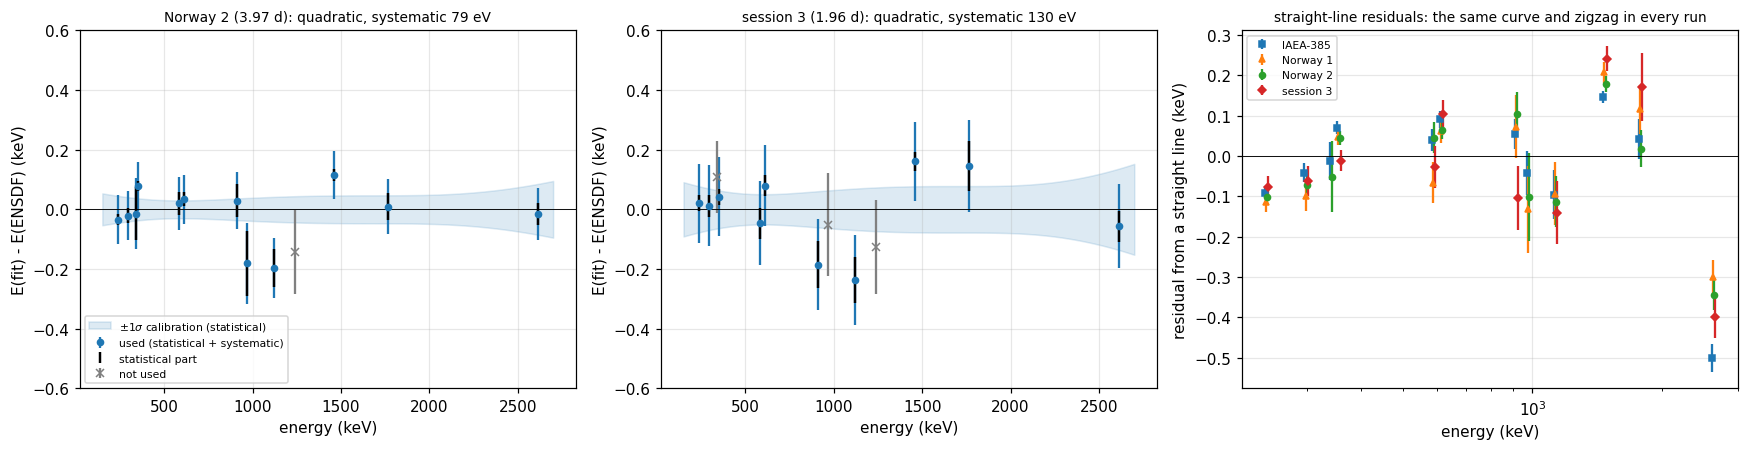

correlation of the straight-line residual patterns (lines used in all four):
           IAEA-385  session 3  Norway 1  Norway 2
IAEA-385       1.00       0.87      0.89      0.96
session 3      0.87       1.00      0.90      0.84
Norway 1       0.89       0.90      1.00      0.93
Norway 2       0.96       0.84      0.93      1.00

position of strong lines in the new run against Norway 2 (gain drift between the runs)
    line  position_new  position_N2  shift_ch  s_shift_ch      z  shift_keV
 238.632      1416.829     1416.612     0.217       0.191  1.134      0.037
 609.321      3618.567     3618.245     0.322       0.243  1.327      0.054
1460.820      8674.453     8673.931     0.522       0.219  2.385      0.088
2614.511     15519.744    15519.833    -0.089       0.381 -0.234     -0.015


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, k in zip(axes[:2], ("Norway 2", NEW_RUN)):
    t, cal = lines[k], cals[k]
    Eg = np.linspace(150, 2700, 300)
    band = cal.sigma(cal.channel(Eg))
    ax.fill_between(Eg, -band, band, color="tab:blue", alpha=0.15, label=r"$\pm1\sigma$ calibration (statistical)")
    u, nu = t[t.used], t[~t.used]
    ax.errorbar(u.E_ref, u.resid_keV, yerr=np.hypot(u.sE_stat, cal.sys), fmt="o", color="tab:blue", ms=4,
                label="used (statistical + systematic)")
    ax.errorbar(u.E_ref, u.resid_keV, yerr=u.sE_stat, fmt="none", ecolor="k", elinewidth=1.6, capsize=0,
                label="statistical part")
    ax.errorbar(nu.E_ref, nu.resid_keV, yerr=nu.sE_stat, fmt="x", color="0.5", ms=5, label="not used")
    ax.axhline(0, color="k", lw=0.6)
    row = cal_summary.set_index("spectrum").loc[k]
    ax.set(ylim=(-0.6, 0.6), xlabel="energy (keV)", ylabel="E(fit) - E(ENSDF) (keV)",
           title=f"{k} ({specs[k].live / 86400:.2f} d): {row.adopted}, systematic {row.sys_eV:.0f} eV")
    ax.title.set_fontsize(9)
axes[0].legend(fontsize=7, loc="lower left")
ax = axes[2]
for k, mk in (("IAEA-385", "s"), ("Norway 1", "^"), ("Norway 2", "o"), (NEW_RUN, "D")):
    u = lines[k][lines[k].used]
    ax.errorbar(u.E_ref * (1 + 0.006 * ["IAEA-385", "Norway 1", "Norway 2", NEW_RUN].index(k)), u.resid_lin_keV,
                yerr=u.sE_stat, fmt=mk, ms=4, label=k, color="tab:red" if k == NEW_RUN else None)
ax.axhline(0, color="k", lw=0.6)
ax.set(xscale="log", xlabel="energy (keV)", ylabel="residual from a straight line (keV)",
       title="straight-line residuals: the same curve and zigzag in every run")
ax.title.set_fontsize(9)
ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "calibration_residuals"); plt.show()

common = pd.concat({k: t.set_index("E_ref").resid_lin_keV[t.set_index("E_ref").used] for k, t in lines.items()
                    if k != BACKGROUND}, axis=1).dropna()
print("correlation of the straight-line residual patterns (lines used in all four):")
print(common.corr().round(2).to_string())

drift = []
for E in (238.632, 609.321, 1460.820, 2614.511):
    a, b = lines[NEW_RUN].set_index("E_ref").loc[E], lines["Norway 2"].set_index("E_ref").loc[E]
    shift = a.position - b.position
    drift.append(dict(line=E, position_new=a.position, position_N2=b.position, shift_ch=shift,
                      s_shift_ch=np.hypot(a.sposition, b.sposition), z=shift / np.hypot(a.sposition, b.sposition),
                      shift_keV=shift * float(cals["Norway 2"].gain(b.position))))
drift = pd.DataFrame(drift)
print("\nposition of strong lines in the new run against Norway 2 (gain drift between the runs)")
table(drift, 3)

### Reading the calibration
Pattern matching found the gain of the new run at once, with 11 reference lines on found peaks. In the full fit 10 of the 13 lines pass the selection, against 12 in Norway 2. The three that fail (Ac-228 at 338.3 and 969.0 keV, Bi-214 at 1238.1 keV) are the weakest lines, with significances of 3.2 to 3.9 standard deviations, below the cut of 5. In Norway 2 the two Ac-228 lines passed with 5.5 and 5.2. This is the first visible cost of the shorter run, because the significance of a line grows as $\sqrt t$ and these lines sit only just above the cut after four days.

The F-test still finds the curvature ($p_F = 0.003$, against $10^{-4}$ for Norway 2), and the quadratic coefficient, $(6.1 \pm 2.4)\times10^{-9}$ keV per channel squared, agrees with that of Norway 2, $(5.4 \pm 1.4)\times10^{-9}$. The straight-line residual pattern of the new run correlates with those of the session-2 spectra (correlation 0.84 to 0.90), so the same non-linearity of the ADC is present, as expected for the same electronics. The per-line systematic needed for $\chi^2/\nu = 1$ is 130 eV, against 79 eV in Norway 2. With only 7 degrees of freedom a systematic is poorly determined, and Section B6 shows that 130 eV lies within the scatter of two-day runs.

The recalibration of Norway 2 in this notebook reproduces the session-2 calibration to 0.000 eV, which proves that the method has not changed between the sessions.

**Gain drift.** The strong lines sit at the same positions as in Norway 2 within 0.1 keV. Only K-40 moved by more than about one standard deviation (+0.09 keV, 2.4σ), while Tl-208 at 2614.5 keV, which would move most under a change of gain, did not move at all (−0.015 keV). There is therefore no evidence for a gain drift between the runs, and K-40 is an odd point that reappears in Sections A4 and B6.

## A4. Peak shape and resolution: is this still the same detector response?

### Why
Every fixed-shape fit in this notebook (inventory, net rates, detection limits, simulations) uses the tail ratio $\tau$ and the resolution model measured in session 2. That is only valid if the detector responds the same way now. Two things could change it. A slow loss of vacuum or a warmer crystal increases trapping and therefore the tail, and electronic noise or a changed shaping setting changes the width. A wrong width in a fixed-shape fit biases the area (too narrow loses counts in the wings, too wide absorbs continuum), so this check protects every rate that follows.

### Method
* **Tail.** For each run on its own we repeat the session-2 profile likelihood. The deviance $D$ summed over the calibration lines is computed for a grid of $\tau$, a parabola through the points near the minimum gives $\hat\tau$, and $\Delta D = 1$ gives its standard error. Doing this for Norway 2 and for the new run separately also gives a first look at Part B, because the error on $\tau$ should grow when the counts halve.
* **Width.** The calibration fits left every width free, so each line has a measured FWHM (of the whole skewed peak). We compare these with the session-2 model and form $\chi^2$ of the new widths against it. If the detector is unchanged, the ratio measured/model scatters around 1 within its errors.

Norway 2  : tau = 0.349 +- 0.113, Gaussian (tau = 0) worse by Delta D = 2.0
session 3 : tau = 0.531 +- 0.193, Gaussian (tau = 0) worse by Delta D = 3.7
session 2 (three spectra together): tau = 0.398 +- 0.063
error ratio new / Norway 2 = 1.71 (pure counting statistics predicts sqrt(2.03) = 1.43)
 spectrum  lines   chi2  ndf     p  mean_ratio_to_model  s_mean_ratio
 Norway 2     12  8.899   12 0.712                0.992         0.013
session 3     10 19.873   10 0.030                1.015         0.019


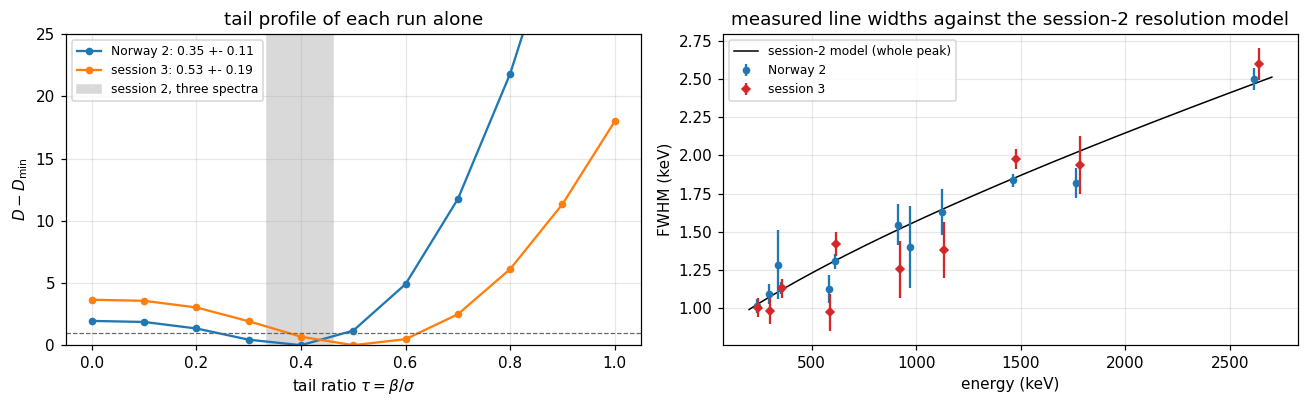

In [6]:
def tau_profile(s, rough, taus=np.round(np.arange(0.0, 1.01, 0.1), 2)):
    # summed deviance of the reference-line fits against the tail ratio, parabola over the same window
    # (tau = 0.2 to 0.6, around the session-2 value) for every run, so that the curvatures are comparable
    D = np.array([G.fit_lines(s, rough, tail_ratio=t, step=STEP)[0].dev.sum() for t in taus])
    near = np.abs(taus - TAU) <= 0.21
    c2, c1, c0 = np.polyfit(taus[near], D[near], 2)
    return taus, D, float(-c1 / (2 * c2)), float(1 / np.sqrt(c2)) if c2 > 0 else np.nan


prof = {k: tau_profile(specs[k], calib[k]["rough"]) for k in ("Norway 2", NEW_RUN)}
for k, (taus, D, t_hat, t_err) in prof.items():
    print(f"{k:10s}: tau = {t_hat:.3f} +- {t_err:.3f}, Gaussian (tau = 0) worse by Delta D = {D[0] - D.min():.1f}")
print(f"session 2 (three spectra together): tau = {TAU:.3f} +- {TAU_ERR:.3f}")
print(f"error ratio new / Norway 2 = {prof[NEW_RUN][3] / prof['Norway 2'][3]:.2f} "
      f"(pure counting statistics predicts sqrt({T_OLD / T_NEW:.2f}) = {np.sqrt(T_OLD / T_NEW):.2f})")

res_rows = []
for k in ("Norway 2", NEW_RUN):
    t = lines[k][lines[k].used]
    gain = cals[k].gain(t.position)
    model = G.fwhm_model(t.E_ref, *WT)
    meas, err = t.fwhm_ch * gain, t.sfwhm_ch * gain
    chi2 = float(np.sum(((meas - model) / err)**2))
    w = 1 / (err / model)**2
    r_mean = float(np.sum(w * meas / model) / w.sum())
    res_rows.append(dict(spectrum=k, lines=len(t), chi2=chi2, ndf=len(t), p=stats.chi2.sf(chi2, len(t)),
                         mean_ratio_to_model=r_mean, s_mean_ratio=float(1 / np.sqrt(w.sum()))))
    lines[k].loc[t.index, "fwhm_keV"] = meas
    lines[k].loc[t.index, "s_fwhm_keV"] = err
res_check = pd.DataFrame(res_rows)
table(res_check, 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for k, (taus, D, t_hat, t_err) in prof.items():
    ax.plot(taus, D - D.min(), "o-", ms=4, label=f"{k}: {t_hat:.2f} +- {t_err:.2f}")
ax.axvspan(TAU - TAU_ERR, TAU + TAU_ERR, color="0.85", label="session 2, three spectra")
ax.axhline(1, color="0.4", ls="--", lw=0.8)
ax.set(ylim=(0, 25), xlabel=r"tail ratio $\tau = \beta/\sigma$", ylabel=r"$D - D_\min$", title="tail profile of each run alone")
ax.legend(fontsize=8)
ax = axes[1]
Eg = np.linspace(200, 2700, 200)
ax.plot(Eg, G.fwhm_model(Eg, *WT), color="k", lw=1, label="session-2 model (whole peak)")
for k, mk, col in (("Norway 2", "o", "tab:blue"), (NEW_RUN, "D", "tab:red")):
    t = lines[k][lines[k].used]
    ax.errorbar(t.E_ref * (1.01 if k == NEW_RUN else 1), t.fwhm_keV, yerr=t.s_fwhm_keV, fmt=mk, ms=4, color=col, label=k)
ax.set(xlabel="energy (keV)", ylabel="FWHM (keV)", title="measured line widths against the session-2 resolution model")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "shape_and_resolution"); plt.show()

### Shape and resolution are unchanged
On its own, each run measures the tail only roughly, $\tau = 0.35 \pm 0.11$ for Norway 2 and $0.53 \pm 0.19$ for the new run, which is why session 2 combined three spectra. Both agree with the session-2 value of $0.40 \pm 0.06$ (within 0.4 and 0.7 standard deviations), so the detector response has not changed and the session-2 shape is valid for the new run. The error on $\tau$ is 1.7 times larger in the new run, roughly the factor $\sqrt{2.03} = 1.43$ expected from counting statistics. Closer agreement cannot be expected from a single pair of runs, because the deviance profile of a tail parameter is not an exact parabola and its curvature varies from one data set to the next.

The widths of the 10 lines of the new run agree with the session-2 model on average (measured over model $= 1.015 \pm 0.019$), as do those of Norway 2 ($0.992 \pm 0.013$). The $\chi^2$ of the new widths is 19.9 for 10 lines ($p = 0.03$), slightly high. The two largest contributions go in opposite directions, Tl-208 at 583.2 keV being narrower than the model (ratio 0.75) and K-40 wider (1.07), which looks like scatter rather than a change of resolution. We keep the session-2 model and return to K-40 in Section B6.

## A5. Which sample is this?

### Why we have to ask
The file name says only "Tuesday test run", and we were told nothing about what sat in the shield. Part B compares the new run with a session-2 run of the same sample, so we must know which one it is, and we would rather prove it from the data than assume it.

### What can tell two sediments apart
The rate of a line is $R = A\,m\,I\,\varepsilon(E)$ (activity concentration, sample mass, emission probability, full-energy efficiency). If the same pot sits in the same place, $m$ and $\varepsilon$ are unchanged, so every line must give the same rate in both runs, within counting statistics. Two lines are especially useful.

* **The Cs-137/K-40 ratio** does not depend on the mass at all, because both lines come from the same pot. K-40 is primordial and set by the mineral content, while Cs-137 was deposited from the atmosphere (weapons tests, Chernobyl) and depends on the layer and the site. Session 2 found that this ratio is 1.67 times higher in Norway 1 than in Norway 2, so it works like a fingerprint.
* **The absolute rates of the sample's own lines** (K-40, Cs-137 and the Th-232 chain) test the mass and placement as well. If the pot were refilled or placed differently, these would all move together.

We leave out the radon daughters (Pb-214, Bi-214), because part of their rate comes from radon in the air inside the shield, which changes between runs whatever sample is there.

### Method
Each line is fitted at its expected energy in every spectrum with the same fixed-shape model, whether or not the search found it. For each candidate $c$ we form
$$ \chi^2_c = \sum_\text{lines}\frac{(R_\text{new} - R_c)^2}{\sigma_\text{new}^2 + \sigma_c^2}, $$
using gross rates. The background cancels in the difference, because it is the same detector and shield, so gross rates avoid adding the background run's uncertainty twice. If the new run measured candidate $c$, $\chi^2_c$ follows a $\chi^2$ distribution with one degree of freedom per line.

In [7]:
SAMPLE_LINES = [("Pb-210", 46.539, []), ("Am-241", 59.5409, []), ("Th-234", 63.29, []), ("Th-234 doublet", 92.59, []),
                ("Ra-226 + U-235", 186.0, []), ("Pb-212", 238.632, [241.995]), ("Pb-214", 295.224, [300.087]),
                ("Pb-214", 351.932, []), ("Tl-208", 583.187, []), ("Bi-214", 609.321, []), ("Cs-137", 661.657, []),
                ("Ac-228", 911.204, []), ("Ac-228", 968.971, [964.766]), ("Bi-214", 1120.294, []), ("K-40", 1460.820, []),
                ("Bi-214", 1764.491, []), ("Tl-208", 2614.511, []), ("Cs-134", 795.864, []), ("Co-60", 1332.492, [])]
ORDER = [f"{n} {E:.1f}" for n, E, _ in SAMPLE_LINES]
GROUP = {**{l: "sample (K, Cs, Th chain)" for l in ["Pb-212 238.6", "Tl-208 583.2", "Cs-137 661.7", "Ac-228 911.2",
                                                     "Ac-228 969.0", "K-40 1460.8", "Tl-208 2614.5"]},
         **{l: "radon daughters" for l in ["Pb-214 295.2", "Pb-214 351.9", "Bi-214 609.3", "Bi-214 1120.3", "Bi-214 1764.5"]}}


def gross_rates(s, cal):
    # every line of SAMPLE_LINES fitted where the calibration puts it, same fixed shape in every spectrum
    rows = []
    for name, E, nb in SAMPLE_LINES:
        p, fit = G.fit_line_at(s, cal, E, sigma_keV, TAU, neighbours=nb)
        x_e = cal.channel(E)
        b_at = fit["theta"][0] + fit["theta"][1] * (x_e - fit["x0"])        # continuum height under the peak, counts/channel
        rows.append(dict(line=f"{name} {E:.1f}", E=E, rate=p["rate"], s_rate=p["s_rate"], area=p["A"], s_area=p["sA"],
                         E_fit=p["E_fit"], pval=p["pval"], cont_per_ch=b_at, sigma_ch=p["sigma"]))
    return pd.DataFrame(rows).set_index("line")


gross = {k: gross_rates(s, cals[k]) for k, s in specs.items()}
fp_lines = [l for l in ORDER if GROUP.get(l) == "sample (K, Cs, Th chain)"]
rows, chi2_fp = [], {}
for c in CANDIDATES:
    a, b = gross[NEW_RUN].loc[fp_lines], gross[c].loc[fp_lines]
    pull = (a.rate - b.rate) / np.hypot(a.s_rate, b.s_rate)
    chi2_fp[c] = (float(np.sum(pull**2)), len(fp_lines))
    for l in fp_lines:
        rows.append(dict(line=l, candidate=c, new_cpd=86400 * a.rate[l], cand_cpd=86400 * b.rate[l],
                         ratio=a.rate[l] / b.rate[l], pull=pull[l]))
fp = pd.DataFrame(rows).pivot(index="line", columns="candidate", values=["cand_cpd", "ratio", "pull"]).reindex(fp_lines)
fp.insert(0, "new_cpd", (86400 * gross[NEW_RUN].rate).reindex(fp_lines))
print("gross rates (counts per day) of the sample's own lines, ratio new/candidate and pull")
print(fp.round(2).to_string())
for c, (chi2, n) in chi2_fp.items():
    print(f"   new run against {c}: chi2 = {chi2:.1f} for {n} lines, p = {stats.chi2.sf(chi2, n):.2g}")

b = gross[BACKGROUND]
csk = {}
for k in [NEW_RUN] + CANDIDATES + [REFERENCE]:
    g = gross[k]
    cs = G.net_rate(g.rate["Cs-137 661.7"], g.s_rate["Cs-137 661.7"], b.rate["Cs-137 661.7"], b.s_rate["Cs-137 661.7"])
    kk = G.net_rate(g.rate["K-40 1460.8"], g.s_rate["K-40 1460.8"], b.rate["K-40 1460.8"], b.s_rate["K-40 1460.8"])
    csk[k] = G.ratio(cs[0], cs[1], kk[0], kk[1])
    print(f"net Cs-137/K-40 rate ratio, {k:10s}: {csk[k][0]:.3f} +- {csk[k][1]:.3f}")
TWIN = min(CANDIDATES, key=lambda c: chi2_fp[c][0])
for c in CANDIDATES:
    d = csk[NEW_RUN][0] - csk[c][0]
    print(f"   new - {c}: {d:+.3f} +- {np.hypot(csk[NEW_RUN][1], csk[c][1]):.3f} "
          f"({d / np.hypot(csk[NEW_RUN][1], csk[c][1]):+.1f} sigma)")
print(f"\nthe new run is the session-2 sample '{TWIN}'; Part B compares with that run")

gross rates (counts per day) of the sample's own lines, ratio new/candidate and pull
              new_cpd cand_cpd             ratio              pull         
candidate             Norway 1 Norway 2 Norway 1 Norway 2 Norway 1 Norway 2
line                                                                       
Pb-212 238.6   458.80   390.94   450.39     1.17     1.02     2.20     0.29
Tl-208 583.2   118.88   112.03   133.74     1.06     0.89     0.43    -1.00
Cs-137 661.7   151.99   242.85   163.85     0.63     0.93    -5.22    -0.77
Ac-228 911.2    78.85    91.70    97.54     0.86     0.81    -0.99    -1.54
Ac-228 969.0    40.61    56.48    41.79     0.72     0.97    -1.43    -0.12
K-40 1460.8    515.93   466.20   498.37     1.11     1.04     2.19     0.82
Tl-208 2614.5  279.58   278.47   251.40     1.00     1.11     0.07     1.86
   new run against Norway 1: chi2 = 40.1 for 7 lines, p = 1.2e-06
   new run against Norway 2: chi2 = 8.2 for 7 lines, p = 0.31
net Cs-137/K-40 rate ratio,

/var/folders/dq/n61t3q053zvgwqg6nb13wh8h0000gn/T/ipykernel_38079/2140932326.py:35: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  fp.insert(0, "new_cpd", (86400 * gross[NEW_RUN].rate).reindex(fp_lines))


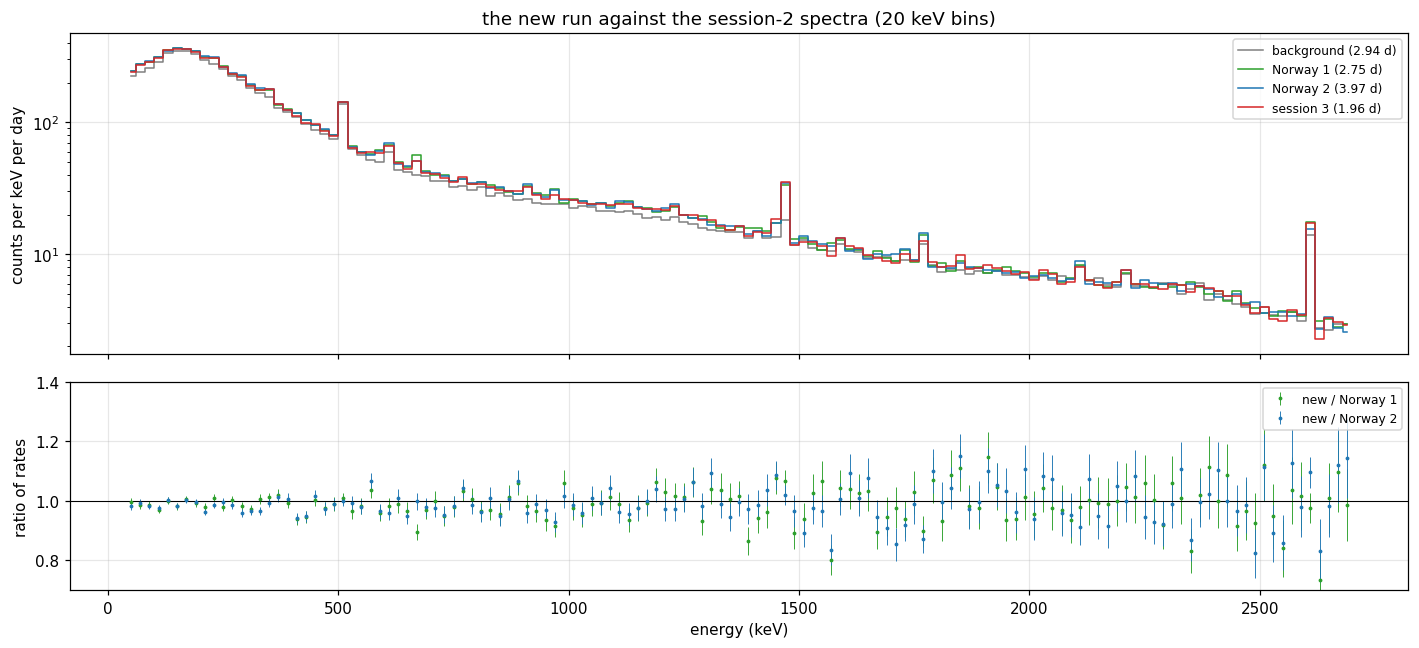

In [8]:
edges = np.arange(40, 2720, 20.0)
cen = 0.5 * (edges[1:] + edges[:-1])
r_new, s_new = G.rebin_to_energy(new, cals[NEW_RUN], edges)
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1.3]))
for k, col in ((BACKGROUND, "0.5"), ("Norway 1", "tab:green"), (TWIN, "tab:blue"), (NEW_RUN, "tab:red")):
    r_, _ = G.rebin_to_energy(specs[k], cals[k], edges)
    axes[0].step(cen, 86400 * r_, where="mid", lw=1, color=col, label=f"{k} ({specs[k].live / 86400:.2f} d)")
axes[0].set(yscale="log", ylabel="counts per keV per day", title="the new run against the session-2 spectra (20 keV bins)")
axes[0].legend(fontsize=8)
for c, col in (("Norway 1", "tab:green"), (TWIN, "tab:blue")):
    r_c, s_c = G.rebin_to_energy(specs[c], cals[c], edges)
    q = r_new / r_c
    axes[1].errorbar(cen, q, yerr=q * np.hypot(s_new / r_new, s_c / r_c), fmt=".", ms=3, color=col, elinewidth=0.6,
                     label=f"new / {c}")
axes[1].axhline(1, color="k", lw=0.7)
axes[1].set(ylim=(0.7, 1.4), xlabel="energy (keV)", ylabel="ratio of rates")
axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "which_sample"); plt.show()

### The new run measured Norway 2
The sample's own lines agree with Norway 2 within statistics ($\chi^2 = 8.2$ for 7 lines, $p = 0.31$) and disagree strongly with Norway 1 ($\chi^2 = 40.1$, $p = 1.2\times10^{-6}$). The decisive line is Cs-137, whose gross rate is 152 counts per day in the new run, against 164 in Norway 2 and 243 in Norway 1 (a pull of −5.2 against Norway 1). The mass-free Cs-137/K-40 rate ratio tells the same story. It is $0.40 \pm 0.05$ in the new run, $0.46 \pm 0.04$ in Norway 2 (−0.9σ) and $0.77 \pm 0.06$ in Norway 1 (−4.7σ). The K-40 and Th-chain rates also match Norway 2 in absolute terms (K-40 ratio 1.04 and Pb-212 ratio 1.02, with errors of 4 and 6 %), which means it was not only the same sediment but also the same amount of it in the same position.

The continuum ratio in the figure is close to 1 for both candidates, because most of the continuum comes from the shield background rather than from the sample, which is why the identification has to rest on the lines. The one bin that stands out is the one containing the Cs-137 line, where the ratio to Norway 1 drops to about 0.9.

Part B therefore compares the new run with Norway 2.

## A6. Every peak in the new spectrum

### Why
The calibration used only 13 lines, and the comparison above only the lines we chose. A complete search is the only way to notice something we did not expect, such as a contamination, a new man-made line or a changed background. It is also the first place where counting time shows directly, since a peak can only be found if it stands out of the noise, and noise grows relative to the signal when the counting time is shorter.

### Method (as in session 2)
A matched-filter search with the width every channel should have from the resolution model, keeping candidates with $S > 5$. Each candidate is fitted with the EMG (width and tail fixed from the models, strong isolated peaks with the width free), and its energy is matched to every library line (ENSDF gamma lines plus annihilation, escape peaks, X-rays and neutron-induced germanium lines) within $\max(0.5\text{ keV}, 3 s_E)$. The same search is run on the four-day Norway 2 spectrum, and peaks are paired across the two runs if their energies agree within 1 keV.

### A candidate is not an identification
A match in energy says only that a library line lies close by. Whether it is that line needs the other lines of the same nuclide, a sensible intensity and the background spectrum, which is why Section A7 then fits the lines that matter one by one.

In [9]:
library = G.build_library()
inv = {k: G.fit_inventory(specs[k], cals[k], sigma_keV, TAU, library) for k in (NEW_RUN, TWIN, BACKGROUND)}
for k, df in inv.items():
    print(f"{k:10s}: {len(df):3d} peaks with S > 5, {np.sum(df.source != 'unidentified'):3d} matched to a library line")
cols = ["E_keV", "sE_keV", "S", "area", "s_area", "rate_cpd", "source", "E_lib", "dE", "other"]
print(f"\n{NEW_RUN} inventory")
with pd.option_context("display.width", 250, "display.max_colwidth", 45):
    print(inv[NEW_RUN][cols].round(2).to_string(index=False))


def pair_peaks(a, b, tol=1.0):
    # which peaks of inventory a have a partner within tol keV in inventory b
    return np.array([np.min(np.abs(b.E_keV.values - E)) < tol if len(b) else False for E in a.E_keV])


inv[TWIN]["in_new"] = pair_peaks(inv[TWIN], inv[NEW_RUN])
inv[NEW_RUN]["in_twin"] = pair_peaks(inv[NEW_RUN], inv[TWIN])
print(f"\nfound in {TWIN} but not in the new run:")
print(inv[TWIN].loc[~inv[TWIN].in_new, ["E_keV", "S", "rate_cpd", "s_rate_cpd", "source"]].round(2).to_string(index=False))
print(f"\nfound in the new run but not in {TWIN}:")
print(inv[NEW_RUN].loc[~inv[NEW_RUN].in_twin, ["E_keV", "S", "rate_cpd", "s_rate_cpd", "source"]].round(2).to_string(index=False))

session 3 :  15 peaks with S > 5,  14 matched to a library line
Norway 2  :  18 peaks with S > 5,  17 matched to a library line
background:   7 peaks with S > 5,   7 matched to a library line

session 3 inventory
  E_keV  sE_keV     S    area  s_area  rate_cpd       source   E_lib    dE            other
  36.22    0.17  6.26  718.22   59.07    367.22 unidentified     NaN   NaN                 
  74.86    0.17  8.84  423.71   38.75    216.64  Bi K-alpha2   74.82  0.04 Pb K-alpha1 75.0
  77.17    0.17  6.29  386.30   36.69    197.51  Bi K-alpha1   77.11  0.06                 
 238.64    0.15 12.05  817.25   52.65    417.85       Pb-212  238.63  0.01                 
 295.23    0.15  8.57  522.27   38.63    267.03       Pb-214  295.22  0.01                 
 351.98    0.15 12.94  887.73   47.55    453.89       Pb-214  351.93  0.04                 
 511.04    0.14  7.91 1439.06   49.54    735.78 annihilation  511.00  0.04     Tl-208 510.8
 583.15    0.15  6.96  227.99   23.38    116.57    

### What the search finds
The new run has 15 peaks with $S > 5$, 14 matched to a library line, and every one of them is also found in Norway 2. The unmatched one at 36.2 keV is the continuum step found in session 2, not a gamma line. Nothing new appears, so no contamination or new source entered between the runs.

Three peaks found in Norway 2 are missing from the new run, the Pb K$\beta$ X-ray at 87.2 keV ($S = 6.6$ in Norway 2), Pb-214 at 241.9 keV ($S = 5.2$) and Bi-214 at 2203.7 keV ($S = 5.3$). In half the time their significance should fall by a factor of about 0.70, to roughly 4.6, 3.7 and 3.7, which is below the threshold of 5. The shorter run therefore sees 15 rather than 18 peaks simply because the weakest lines sink into the noise. Section B6 shows that a simulated two-day run of Norway 2 finds $14.7 \pm 1.1$ peaks, so 15 is exactly what counting statistics predict.

## A7. Net rates and mass-free activity ratios

### Why subtract the background
Every line in the empty-shield background (radon in the shield air, the walls, the detector's own materials) is also present when the sample sits in the shield. The part that belongs to the sample is
$$ R_\text{net} = \frac{N_s}{t_s} - \frac{N_b}{t_b}, \qquad \sigma_R^2 = \frac{\sigma_{N_s}^2}{t_s^2} + \frac{\sigma_{N_b}^2}{t_b^2}, $$
where the variances add because the two runs are independent. The only background run is the one of 12 to 15 October (2.94 days), so it is used for both the new run and Norway 2. This will matter in Part B, because the background term does not shrink when the sample is counted for longer.

### Activity ratios without masses
The masses of the pots are still unknown. As in session 2 we remove them with IAEA-385, measured in the same geometry. For two lines X and Y in the same pot the mass cancels, and the efficiency ratio is the same for the sample and the reference, so
$$ \left(\frac{A_X}{A_Y}\right)_\text{sample} = \frac{(R_X/R_Y)_\text{sample}}{(R_X/R_Y)_\text{IAEA-385}}\left(\frac{A_X}{A_Y}\right)_\text{IAEA-385}. $$
The certificate values are decayed from 1 January 2019 to the middle of the IAEA-385 run, and their expanded uncertainties ($k = 2$) are halved to standard uncertainties. The same background run is subtracted from the sample and from IAEA-385, hence its error enters the ratio once, through $\partial \ln q/\partial B_X = 1/R^r_X - 1/R^s_X$ and $\partial \ln q/\partial B_Y = 1/R^s_Y - 1/R^r_Y$. These activities are relative to IAEA-385. Between the Norway 2 run and the new run (four days apart) Cs-137 decays by $1 - 2^{-4/(30.08 \times 365.25)} = 0.025\,\%$, which is negligible, so the two runs of the same sediment must give the same ratios.

### Caveats carried over from session 2
The sample shields part of the external background, so subtracting the empty-shield run slightly over-subtracts, most at low energy. Radon in the shield air is not constant, so the radon-daughter lines carry an extra, unknown uncertainty in every run, which Part B tests directly.

In [10]:
def net_table(names):
    rows = []
    b = gross[BACKGROUND]
    for k in names:
        g = gross[k]
        for line in ORDER:
            R, sR, z = G.net_rate(g.rate[line], g.s_rate[line], b.rate[line], b.s_rate[line])
            rows.append(dict(spectrum=k, line=line, gross_cpd=86400 * g.rate[line], s_gross_cpd=86400 * g.s_rate[line],
                             bkg_cpd=86400 * b.rate[line], s_bkg_cpd=86400 * b.s_rate[line],
                             net_cpd=86400 * R, s_net_cpd=86400 * sR, z=z))
    return pd.DataFrame(rows)


net = net_table([NEW_RUN, TWIN, "Norway 1", REFERENCE])
wide = net[net.spectrum.isin([NEW_RUN, TWIN])].pivot(index="line", columns="spectrum",
                                                     values=["net_cpd", "s_net_cpd", "z"]).reindex(ORDER)
print("net rates (counts per day of live time), their errors and significance z")
print(wide.round(1).to_string())

rm = REFERENCE_MATERIAL
t_y = (rm["measured_mid_date"] - rm["reference_date"]).days / 365.25
A_ref = {"K-40": rm["K40"], "Cs-137": (rm["Cs137"][0] * 2**(-t_y / 30.08), rm["Cs137"][1] * 2**(-t_y / 30.08)),
         "Th-232": rm["Th232"], "Ra-226": rm["Ra226"]}
get = lambda k, line: net[(net.spectrum == k) & (net.line == line)].iloc[0]
RATIO_LINES = [("Cs-137 661.7", "Cs-137"), ("Pb-212 238.6", "Th-232"), ("Tl-208 583.2", "Th-232"),
               ("Ac-228 911.2", "Th-232"), ("Pb-214 351.9", "Ra-226"), ("Bi-214 609.3", "Ra-226")]


def activity_ratio(k, line, act):
    # (A_X/A_K)_sample = (R_X/R_K)_sample / (R_X/R_K)_IAEA-385 * (A_X/A_K)_certificate
    # The same background run is subtracted in the sample and in IAEA-385, so its error enters once, through the
    # derivative of ln q with respect to each background rate, d ln q / d B_X = -1/X_s + 1/X_r, d ln q / d B_K = 1/K_s - 1/K_r.
    xs, ks, xr, kr = get(k, line), get(k, "K-40 1460.8"), get(REFERENCE, line), get(REFERENCE, "K-40 1460.8")
    q = (xs.net_cpd / ks.net_cpd) / (xr.net_cpd / kr.net_cpd)
    var_log = ((xs.s_gross_cpd / xs.net_cpd)**2 + (ks.s_gross_cpd / ks.net_cpd)**2
               + (xr.s_gross_cpd / xr.net_cpd)**2 + (kr.s_gross_cpd / kr.net_cpd)**2
               + (xs.s_bkg_cpd * (1 / xr.net_cpd - 1 / xs.net_cpd))**2
               + (ks.s_bkg_cpd * (1 / ks.net_cpd - 1 / kr.net_cpd))**2
               + (A_ref[act][1] / A_ref[act][0])**2 + (A_ref["K-40"][1] / A_ref["K-40"][0])**2)
    value = q * A_ref[act][0] / A_ref["K-40"][0]
    return value, value * np.sqrt(var_log)


rows = []
for line, act in RATIO_LINES:
    row = {"ratio": f"{act}/K-40 from {line}"}
    for k in (NEW_RUN, TWIN, "Norway 1"):
        v, sv = activity_ratio(k, line, act)
        row[k], row[f"s {k}"] = v, sv
    row[f"z (new - {TWIN})"] = (row[NEW_RUN] - row[TWIN]) / np.hypot(row[f"s {NEW_RUN}"], row[f"s {TWIN}"])
    rows.append(row)
act_ratios = pd.DataFrame(rows)
print("\nactivity ratios (Bq per Bq of K-40), calibrated with IAEA-385 in the same geometry, no masses needed")
table(act_ratios, 4)
print("(the z column ignores that both runs share the background and IAEA-385 runs, so it is conservative)")
print(f"for comparison IAEA-385 itself: Cs-137/K-40 = {A_ref['Cs-137'][0] / A_ref['K-40'][0]:.4f}, "
      f"Th-232/K-40 = {A_ref['Th-232'][0] / A_ref['K-40'][0]:.4f}, Ra-226/K-40 = {A_ref['Ra-226'][0] / A_ref['K-40'][0]:.4f}")

net rates (counts per day of live time), their errors and significance z
                      net_cpd           s_net_cpd                  z          
spectrum             Norway 2 session 3  Norway 2 session 3 Norway 2 session 3
line                                                                          
Pb-210 46.5              -8.3      11.7      16.6      20.3     -0.5       0.6
Am-241 59.5               4.6      19.7      16.0      20.4      0.3       1.0
Th-234 63.3               9.6       9.0      16.6      20.1      0.6       0.4
Th-234 doublet 92.6      33.8      50.2      17.7      21.8      1.9       2.3
Ra-226 + U-235 186.0     75.0      96.9      21.1      25.6      3.5       3.8
Pb-212 238.6            405.3     413.7      22.4      28.0     18.1      14.8
Pb-214 295.2            177.0     152.0      20.1      24.0      8.8       6.3
Pb-214 351.9            280.4     229.4      21.0      25.7     13.3       8.9
Tl-208 583.2            120.1     105.2      11.3      13.

### The same activity ratios from both runs
The two runs give the same activity ratios within their errors. Cs-137/K-40 is $0.0243 \pm 0.0028$ from the new run and $0.0277 \pm 0.0024$ from Norway 2, close to that of IAEA-385 (0.0271) and well below Norway 1 (0.046). Th-232/K-40 from Pb-212 is $0.068 \pm 0.006$ against $0.070 \pm 0.005$. The largest difference is Ra-226/K-40 from Pb-214 at 351.9 keV, $0.058 \pm 0.007$ against $0.074 \pm 0.007$ (1.7σ).

The errors of the new run are larger, as they must be, and Part B measures by how much and explains why. One pattern deserves attention already. All the radon-daughter ratios come out lower in the new run, and Section B7 shows that this is not an accident of the sample but a change of radon in the shield between the runs.

# Part B. Two days against four: what counting time does to the data

## B1. What halving the counting time should change, and what it should not

### The question
Part A showed that the new run measured the same pot of Norway 2 sediment, on the same detector, a day after the session-2 run of 3.97 days, but for only 1.96 days of live time. Everything that depends on the sample, the detector and the geometry is therefore the same, and the counting time is the main thing that differs. This is a natural experiment on counting time. Before measuring anything, we write down what counting statistics predict, so that each later result can be compared with a number fixed in advance rather than explained after the fact.

### Counting statistics
Radioactive decays are independent and rare events, so the number of counts $N$ recorded in a channel, or in a peak, during a live time $t$ follows a Poisson distribution with mean $\lambda t$, where $\lambda$ is the true rate. Its variance equals its mean, so
$$ \sigma_N = \sqrt{\lambda t}, \qquad \frac{\sigma_N}{N} = \frac{1}{\sqrt{\lambda t}}, \qquad R = \frac{N}{t}, \qquad \sigma_R = \sqrt{\frac{\lambda}{t}} . $$
The rate itself does not depend on $t$, but its uncertainty falls as $1/\sqrt t$. With $t_\text{old}/t_\text{new} = 2.03$ every purely statistical uncertainty of the new run should therefore be $\sqrt{2.03} = 1.43$ times larger than in Norway 2, never twice as large. This square root is the central fact of Part B, and it means that halving the uncertainty costs four times the counting time.

### What follows from it
* **Noise.** The channel-to-channel fluctuation of a smooth continuum is $\sqrt{\bar n}$ for a mean content $\bar n$, so relative to the signal it is $1/\sqrt{\bar n} \propto 1/\sqrt t$. The spectrum looks rougher, but the noise is still pure Poisson, with no extra noise from the electronics.
* **A peak area.** A fitted area $A$ sitting on a continuum of $B$ counts under the peak has, roughly, $\sigma_A^2 \approx A + 2B$, since the continuum has to be estimated from neighbouring channels and subtracted. Both $A$ and $B$ grow in proportion to $t$, so $\sigma_A \propto \sqrt t$, the rate error scales as $1/\sqrt t$ and the **significance** $z = A/\sigma_A$ grows as $\sqrt t$. The new run's significances should be $1/1.43 = 0.70$ of the old ones.
* **A net rate.** The background run is the same 2.94-day file for both runs, so
$$ \sigma_\text{net}^2 = \underbrace{\sigma_G^2(t)}_{\propto 1/t} + \underbrace{\sigma_B^2}_{\text{fixed}} , $$
and the net-rate error grows by less than 1.43, by an amount that depends on how large the background term is for each line.
* **Detection limits.** Currie's detection limit (Section B4) for a line on a continuum of $B$ counts is $L_D = 2.71 + 4.65\sqrt{B}$ counts. With $B = bt$, the smallest detectable rate is $L_D/t \approx 4.65\sqrt{b/t}$ when $B$ is large, which again rises by 1.43, and $2.71/t$ when $B$ is tiny, which rises by the full factor of 2.03.
* **Calibration.** The position of a peak is known to about $\sigma_\text{peak}/\sqrt{A}$, so the statistical part of every calibration point grows by 1.43. Weak lines fall below the $5\sigma$ selection and are lost, and the F-test sees the curvature less clearly.

### What should not change
The true rates, the line energies, the resolution, the peak shape and the efficiency belong to the sample and the detector, not to the counting time. Their **estimates** become less precise, but an unbiased estimator stays centred on the same value. So halving the time should reduce **precision** (the scatter of repeated measurements) by 1.43 but leave **accuracy** (the closeness of the average to the truth) unchanged.

### Where real data can depart from this simple picture
1. **Systematic floors that do not average down.** The ADC non-linearity (the per-line systematic of the calibration), the background and reference runs, and the certificate uncertainty are the same however long the sample is counted.
2. **Estimators that are biased at low counts.** A fitted area that is not allowed to go negative is biased upwards when the true area is near zero, and the bias is proportional to $\sigma \propto 1/\sqrt t$. Ratios and thresholds behave similarly. So accuracy can depend on time for weak lines.
3. **Things that change in time.** Radon in the shield air, the cosmic-ray rate (which follows atmospheric pressure) and the gain of the electronics vary on scales of hours to days. Two runs at different times average different conditions, which no amount of counting removes, and a long run integrates more gain drift into each peak.

Sections B2 to B5 measure each prediction in the two real runs. Section B6 simulates hundreds of two-day and four-day runs of the same sample, which separates the effect of counting time from everything else. Section B7 then tests whether the remaining differences between the real runs are statistical, and Section B8 asks how long one should count.

In [11]:
p_t = T_NEW / T_OLD
print(f"live time new / old = {T_NEW / 86400:.4f} d / {T_OLD / 86400:.4f} d = {p_t:.4f}")
print(f"predicted from Poisson statistics, new relative to old:")
print(f"   counts in any region            x {p_t:.3f}")
print(f"   error of a gross rate           x {1 / np.sqrt(p_t):.3f}")
print(f"   significance of a line          x {np.sqrt(p_t):.3f}")
print(f"   detection limit (rate), B >> 1  x {1 / np.sqrt(p_t):.3f}")
print(f"   detection limit (rate), B << 1  x {1 / p_t:.3f}")
print(f"   time needed to halve an error   x 4")

live time new / old = 1.9558 d / 3.9740 d = 0.4922
predicted from Poisson statistics, new relative to old:
   counts in any region            x 0.492
   error of a gross rate           x 1.425
   significance of a line          x 0.702
   detection limit (rate), B >> 1  x 1.425
   detection limit (rate), B << 1  x 2.032
   time needed to halve an error   x 4


## B2. Noise: how rough is the spectrum, and is it only counting statistics?

### Why
"Noise" in a spectrum is the random scatter of the channel contents around the smooth curve they would follow with infinite counting time. Two things could make a short run noisier than a long one. The first is plain Poisson statistics, which we can predict exactly. The second would be extra noise, for example electronic spikes, pile-up or an unstable baseline, which would add variance beyond Poisson. We need to know which one we see, because only the first is cured by counting longer.

### Method: adjacent channels, no model needed
Comparing the counts with a fitted smooth curve would make the answer depend on the curve. Instead we use pairs of neighbouring channels. If two adjacent channels have nearly the same mean $\mu$ (true for a continuum, whose slope over one channel of 0.17 keV is tiny), then their difference $d = n_i - n_{i+1}$ has mean 0 and variance $\mu_i + \mu_{i+1}$ (the variances of independent counts add). The ratio
$$ D = \frac{\sum d^2}{\sum (n_i + n_{i+1})} $$
is then 1 for pure Poisson noise, above 1 for extra noise and below 1 if counts were correlated between channels. Its standard error follows from the fourth moment of the difference of two Poisson variables, $\operatorname{Var}(d^2) = 2m^2 + m$ with $m = \mu_i + \mu_{i+1}$. We use disjoint pairs, so that no channel enters twice, and exclude the 36 keV step and everything within three FWHM of any peak found in either run or listed in Section A5.

The per-channel relative noise is $\sqrt{\overline{d^2}/2}/\bar n$, the standard deviation of one channel divided by its mean. Since the rates are the same in both runs, the ratio of relative noise (new over old) should equal $\sqrt{\bar n_\text{old}/\bar n_\text{new}} \approx 1.43$.

### What would go wrong without it
If extra noise were present, every uncertainty from a Poisson fit would be too small, and every significance too large, in both runs. A rough-looking short spectrum might also tempt one to smooth it, which hides real structure and correlates neighbouring channels.

band (keV)  pairs  counts/ch old  D old  sD old  rel noise old (%)  counts/ch new  D new  sD new  rel noise new (%)  noise ratio new/old  predicted sqrt(n_old/n_new)
    40-200    359        217.878  0.997   0.076              6.764        106.490  1.125   0.076             10.278                1.519                        1.430
   200-500    822        113.319  0.951   0.054              9.161         54.749  1.034   0.054             13.744                1.500                        1.439
  500-1000   1280         26.726  1.005   0.042             19.392         13.082  1.008   0.042             27.752                1.431                        1.429
 1000-1600   1684         12.287  1.039   0.037             29.078          5.974  0.996   0.038             40.838                1.404                        1.434
 1600-2700   3140          4.315  1.003   0.029             48.202          2.119  0.994   0.031             68.480                1.421                        1.427


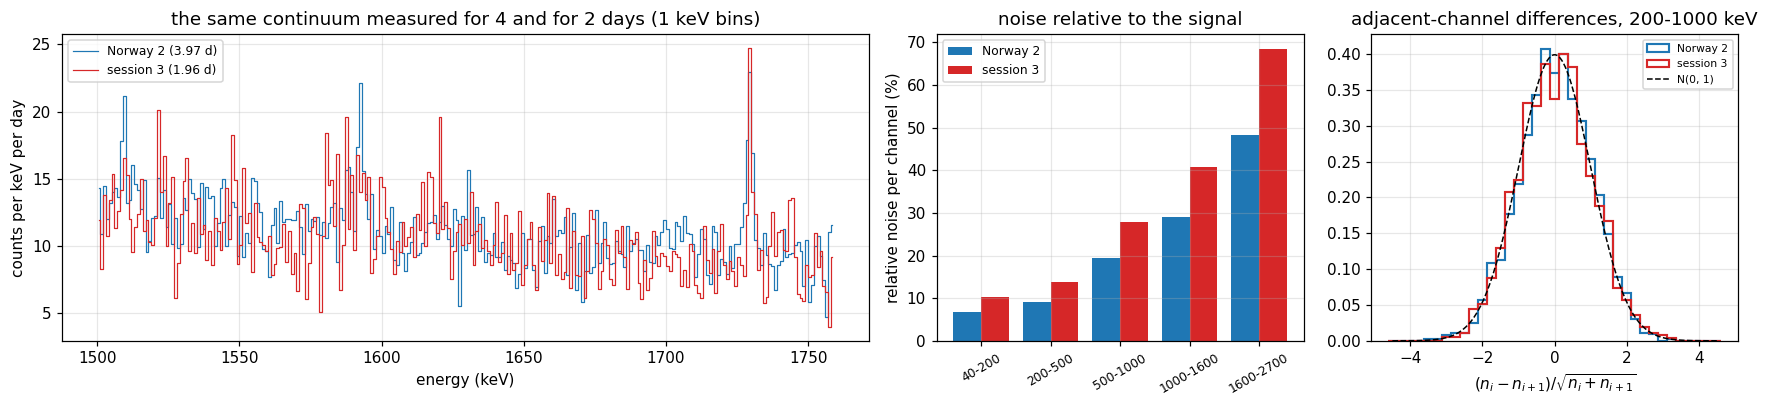

In [12]:
BANDS = [(40, 200), (200, 500), (500, 1000), (1000, 1600), (1600, 2700)]


def quiet_channels(s, cal, peak_E):
    # True for channels farther than 3 FWHM from every listed peak and outside the 36 keV step and 511 keV
    E = cal.energy(s.channels)
    keep = (E > 40) & (E < 2700) & (np.abs(E - 511.0) > 8)
    for Ep in peak_E:
        keep &= np.abs(E - Ep) > 3 * G.fwhm_model(Ep, *WT)
    return keep


def dispersion(s, cal, keep, lo, hi):
    # adjacent-channel test: D = sum d^2 / sum(n_i + n_i+1) = 1 for Poisson noise
    i0, i1 = int(np.ceil(cal.channel(lo))), int(np.floor(cal.channel(hi)))
    i = np.arange(i0, i1 - 1, 2)
    i = i[keep[i] & keep[i + 1]]
    a, b = s.counts[i].astype(float), s.counts[i + 1].astype(float)
    m = a + b
    return dict(D=np.sum((a - b)**2) / m.sum(), sD=np.sqrt(np.sum(2 * m**2 + m)) / m.sum(),
                rel_noise=np.sqrt(np.mean((a - b)**2) / 2) / np.mean(m / 2), mean_counts=np.mean(m / 2), pairs=len(i))


peak_E = np.r_[inv[TWIN].E_keV, inv[NEW_RUN].E_keV, [E for _, E, _ in SAMPLE_LINES]]
rows = []
for lo, hi in BANDS:
    r = {"band (keV)": f"{lo}-{hi}"}
    for k in (TWIN, NEW_RUN):
        d = dispersion(specs[k], cals[k], quiet_channels(specs[k], cals[k], peak_E), lo, hi)
        tag = "old" if k == TWIN else "new"
        r.update({f"pairs": d["pairs"], f"counts/ch {tag}": d["mean_counts"], f"D {tag}": d["D"], f"sD {tag}": d["sD"],
                  f"rel noise {tag} (%)": 100 * d["rel_noise"]})
    r["noise ratio new/old"] = r["rel noise new (%)"] / r["rel noise old (%)"]
    r["predicted sqrt(n_old/n_new)"] = np.sqrt(r["counts/ch old"] / r["counts/ch new"])
    rows.append(r)
noise = pd.DataFrame(rows)
table(noise, 3)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
ax = axes[0]
edges = np.arange(1500, 1760, 1.0)
cen = 0.5 * (edges[1:] + edges[:-1])
for k, col in ((TWIN, "tab:blue"), (NEW_RUN, "tab:red")):
    r_, _ = G.rebin_to_energy(specs[k], cals[k], edges)
    ax.step(cen, 86400 * r_, where="mid", lw=0.8, color=col, label=f"{k} ({specs[k].live / 86400:.2f} d)")
ax.set(xlabel="energy (keV)", ylabel="counts per keV per day", title="the same continuum measured for 4 and for 2 days (1 keV bins)")
ax.legend(fontsize=8)
ax = axes[1]
x = np.arange(len(noise))
ax.bar(x - 0.2, noise["rel noise old (%)"], 0.4, color="tab:blue", label=TWIN)
ax.bar(x + 0.2, noise["rel noise new (%)"], 0.4, color="tab:red", label=NEW_RUN)
ax.set(xticks=x, ylabel="relative noise per channel (%)", title="noise relative to the signal")
ax.set_xticklabels(noise["band (keV)"], rotation=30, fontsize=8)
ax.legend(fontsize=8)
ax = axes[2]
grid = np.linspace(-4.5, 4.5, 200)
for k, col in ((TWIN, "tab:blue"), (NEW_RUN, "tab:red")):
    s, cal = specs[k], cals[k]
    keep = quiet_channels(s, cal, peak_E)
    i = np.arange(int(cal.channel(200)), int(cal.channel(1000)), 2)
    i = i[keep[i] & keep[i + 1]]
    a, b = s.counts[i].astype(float), s.counts[i + 1].astype(float)
    # bins centred on 0, because d = n_i - n_i+1 is an integer and d = 0 must not sit on a bin edge
    ax.hist((a - b) / np.sqrt(np.clip(a + b, 1, None)), bins=np.arange(-4.625, 4.7, 0.25), density=True, histtype="step",
            color=col, lw=1.4, label=k)
ax.plot(grid, stats.norm.pdf(grid), "k--", lw=1, label="N(0, 1)")
ax.set(xlabel=r"$(n_i - n_{i+1})/\sqrt{n_i + n_{i+1}}$", title="adjacent-channel differences, 200-1000 keV")
ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "noise"); plt.show()

### The shorter run is noisier, and only by Poisson statistics
In every band the dispersion $D$ is consistent with 1 in both runs (0.95 to 1.04 in Norway 2, 0.99 to 1.13 in the new run, with errors of 0.03 to 0.08). The largest deviation, $1.13 \pm 0.08$ for the new run between 40 and 200 keV, is 1.6σ, and that is also the region where weak unlisted X-ray peaks are densest. So both spectra carry pure counting noise, with no electronic noise added in either run. The histograms of normalised adjacent-channel differences follow the standard normal curve for both runs, which shows the same thing graphically.

The relative noise per channel is 1.40 to 1.52 times larger in the new run, against 1.43 predicted from the mean counts, so the visibly rougher look of the two-day spectrum in the left panel is exactly the Poisson expectation. To give a feel for the numbers, a channel between 500 and 1000 keV holds about 13 counts after two days and fluctuates by 28 % from one channel to the next, against 27 counts and 19 % after four days.

**Why it arises.** The variance of a Poisson count equals its mean, so the absolute noise grows as $\sqrt t$ while the signal grows as $t$, and their ratio falls as $1/\sqrt t$. Halving the time raises the relative noise by $\sqrt{2.03} = 1.43$, not by 2.

**What can be done about it.** Only more counts reduce it. Summing neighbouring channels lowers the relative noise of each bin in the same way, but at the price of energy detail, so it trades resolution against noise without creating information.

## B3. Precision and significance of every line

### Why
The numbers we finally use are line rates, so the most direct measure of quality is how well each rate is determined. We compare three things line by line, each against its prediction from Section B1.

1. **The error of the gross rate**, $\sigma_G$, from the Poisson fit. Prediction: $\sigma_G^\text{new}/\sigma_G^\text{old} = \sqrt{t_\text{old}/t_\text{new}} = 1.43$.
2. **The error of the net rate**, which includes the fixed background-run term. Prediction for each line:
$$ \frac{\sigma_\text{net}^\text{new}}{\sigma_\text{net}^\text{old}} = \sqrt{\frac{\sigma_{G,\text{old}}^2\,t_\text{old}/t_\text{new} + \sigma_B^2}{\sigma_{G,\text{old}}^2 + \sigma_B^2}} , $$
which lies between 1 (background-dominated lines) and 1.43 (lines with negligible background).
3. **The significance** $z = R_\text{net}/\sigma_\text{net}$. If the true net rate is the same, $z_\text{new}/z_\text{old} = \sigma_\text{net}^\text{old}/\sigma_\text{net}^\text{new}$. Individual $z$ values also scatter by about $\pm 1$ because the rates themselves fluctuate, so we compare the trend, not single lines.

The fits use the same fixed shape and the same lines in both runs, so any difference is in the data.

                line  z_old  z_new  rel_err_old_pct  rel_err_new_pct  gross_err_ratio  net_err_ratio  net_err_ratio_pred  bkg_share_of_var_old
         Pb-210 46.5 -0.503  0.577          198.769          173.172            1.457          1.229               1.212                 0.546
         Am-241 59.5  0.289  0.966          345.544          103.556            1.566          1.279               1.205                 0.563
         Th-234 63.3  0.576  0.449          173.619          222.583            1.459          1.211               1.194                 0.587
 Th-234 doublet 92.6  1.910  2.306           52.365           43.371            1.442          1.228               1.219                 0.530
Ra-226 + U-235 186.0  3.545  3.787           28.208           26.403            1.421          1.210               1.213                 0.544
        Pb-212 238.6 18.110 14.778            5.522            6.767            1.413          1.251               1.259                 0.433

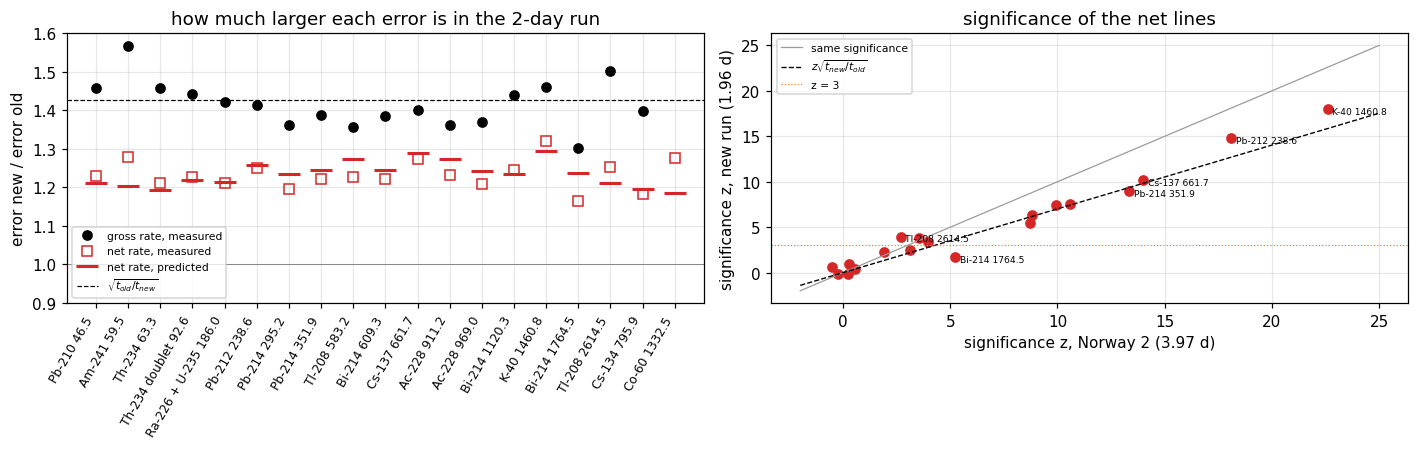

In [13]:
rows = []
b = gross[BACKGROUND]
for line in ORDER:
    go, gn = gross[TWIN].loc[line], gross[NEW_RUN].loc[line]
    no, nn = get(TWIN, line), get(NEW_RUN, line)
    sB = 86400 * b.s_rate[line]
    pred_net = np.sqrt(((86400 * go.s_rate)**2 * T_OLD / T_NEW + sB**2) / ((86400 * go.s_rate)**2 + sB**2))
    rows.append(dict(line=line, z_old=no.z, z_new=nn.z, rel_err_old_pct=100 * no.s_net_cpd / abs(no.net_cpd),
                     rel_err_new_pct=100 * nn.s_net_cpd / abs(nn.net_cpd),
                     gross_err_ratio=gn.s_rate / go.s_rate, net_err_ratio=nn.s_net_cpd / no.s_net_cpd,
                     net_err_ratio_pred=pred_net, bkg_share_of_var_old=sB**2 / no.s_net_cpd**2))
prec = pd.DataFrame(rows)
table(prec, 3)
strong = prec[prec.z_old > 3]
print(f"\nlines detected in the old run (z > 3): {len(strong)}")
print(f"   gross-rate error ratio: mean {strong.gross_err_ratio.mean():.3f}, range {strong.gross_err_ratio.min():.3f} "
      f"to {strong.gross_err_ratio.max():.3f} (prediction {np.sqrt(T_OLD / T_NEW):.3f})")
print(f"   net-rate error ratio  : mean {strong.net_err_ratio.mean():.3f} (predicted mean {strong.net_err_ratio_pred.mean():.3f})")
zr = np.sum(strong.z_new * strong.z_old) / np.sum(strong.z_old**2)
print(f"   significance: least-squares slope z_new / z_old = {zr:.3f} (prediction from the error ratios "
      f"{np.mean(1 / strong.net_err_ratio_pred):.3f}, from counting time alone {np.sqrt(T_NEW / T_OLD):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
x = np.arange(len(prec))
ax.plot(x, prec.gross_err_ratio, "o", color="k", label="gross rate, measured")
ax.plot(x, prec.net_err_ratio, "s", color="tab:red", mfc="none", label="net rate, measured")
ax.plot(x, prec.net_err_ratio_pred, "_", color="tab:red", ms=14, mew=2, label="net rate, predicted")
ax.axhline(np.sqrt(T_OLD / T_NEW), color="k", ls="--", lw=0.8, label=r"$\sqrt{t_{old}/t_{new}}$")
ax.axhline(1, color="0.5", lw=0.6)
ax.set(xticks=x, ylabel="error new / error old", ylim=(0.9, 1.6), title="how much larger each error is in the 2-day run")
ax.set_xticklabels(prec.line, rotation=60, ha="right", fontsize=8)
ax.legend(fontsize=7)
ax = axes[1]
ax.plot(prec.z_old, prec.z_new, "o", color="tab:red")
for r in prec.itertuples():
    if r.line in ("K-40 1460.8", "Pb-212 238.6", "Cs-137 661.7", "Bi-214 1764.5", "Tl-208 2614.5", "Pb-214 351.9"):
        ax.annotate(r.line, (r.z_old, r.z_new), fontsize=6, xytext=(3, -3), textcoords="offset points")
zz = np.linspace(-2, 25, 10)
ax.plot(zz, zz, color="0.6", lw=0.8, label="same significance")
ax.plot(zz, np.sqrt(T_NEW / T_OLD) * zz, "k--", lw=0.9, label=r"$z\sqrt{t_{new}/t_{old}}$")
ax.axhline(3, color="tab:orange", lw=0.8, ls=":", label="z = 3")
ax.set(xlabel="significance z, Norway 2 (3.97 d)", ylabel="significance z, new run (1.96 d)", title="significance of the net lines")
ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "precision_and_significance"); plt.show()

### Errors grow by 1.43 for gross rates, and by less after background subtraction
For the 12 lines detected in Norway 2, the gross-rate errors are on average 1.39 times larger in the new run (range 1.30 to 1.46), close to the predicted 1.43. They scatter around the prediction because each error is computed from the counts actually observed, and the new run has somewhat lower rates in the radon lines (Section B7).

The net-rate errors grow by only 1.23 on average, in close agreement with the per-line prediction of 1.25. The reason is the background run. For a typical line 35 to 60 % of the net-rate variance of Norway 2 came from the 2.94-day background spectrum (last column), and that part is identical for both runs. The sample's own counting error grows by 1.43, but it adds in quadrature to a term that does not change, so the total grows less. The relative precision of the K-40 net rate goes from 4.4 % to 5.6 %, that of Cs-137 from 7.1 % to 9.8 %.

The significance falls accordingly. The least-squares slope of $z_\text{new}$ against $z_\text{old}$ is 0.75, between the 0.70 of counting time alone and the 0.80 predicted with the fixed background term. K-40 drops from 22.6σ to 18.0σ and Cs-137 from 14.0σ to 10.2σ, both still overwhelming. Lines near the detection threshold suffer most. Ac-228 at 969.0 keV falls from 3.1σ to 2.5σ, and Bi-214 at 1764.5 keV from 5.2σ to 1.7σ. The second drop is far larger than counting time explains, and Section B7 traces it to the radon in the shield. Tl-208 at 2614.5 keV goes the other way (2.7σ to 3.9σ), a reminder that a single line's significance also fluctuates by about one unit from run to run.

## B4. Detection limits: how weak a line can we still see?

### Why
For a nuclear-forensics question the absence of a line is often as important as its presence (no Am-241 means no plutonium fallout signature, no Cs-134 means no recent reactor release). "Not detected" is only meaningful together with a number saying how large a signal could have hidden in the noise. That number depends directly on the counting time, so it is one of the clearest ways to state what a shorter run costs.

### Currie's limits, derived
Suppose a region of interest (ROI) holds $B$ continuum counts, estimated from about as many channels beside the peak, so that the net counts $S$ have standard deviation $\sigma_0 = \sqrt{2B}$ when there is no line. Two different errors are possible.

* **False detection.** We claim a line if $S > L_C$, and choose the **decision threshold** $L_C = k\sigma_0$ with $k = 1.645$, so that pure noise exceeds it only 5 % of the time. This gives $L_C = 1.645\sqrt{2B} = 2.33\sqrt{B}$.
* **Missed detection.** A real line of mean $L_D$ must exceed $L_C$ in 95 % of measurements, so $L_D = L_C + k\sigma_D$ with $\sigma_D^2 = L_D + 2B$. Solving this quadratic for $L_D$ gives exactly
$$ L_D = k^2 + 2k\sqrt{2B} = 2.71 + 4.65\sqrt{B} \quad\text{counts}. $$

$L_D$ is the **detection limit**, the smallest true signal we would reliably see. It is fixed before measuring, from the continuum alone, which is why it is the right number for comparing two counting times. We take the ROI as $\pm 1.25$ FWHM around the top of the line, the mode of the tailed peak (FWHM from the resolution model), read $B$ from the fitted continuum under the line, divide by the fraction $f$ of the EMG peak inside the ROI and by the live time, and so obtain the smallest detectable gross rate, $L_D/(f\,t)$.

### Scaling with time
$B = bt$ grows with $t$, so the detectable rate is $(2.71 + 4.65\sqrt{bt})/(f t)$. In this detector even the quietest ROIs hold tens of counts in two days, so the $\sqrt{B}$ term dominates and the limit should rise by close to 1.43. We also show how the limit falls with longer counting for one line, to see what it costs to push it down.

### Scope
This limit concerns the continuum only. For a line that is also present in the background spectrum (Pb-210 at 46.5 keV from the lead shield, for example), the background run's own uncertainty adds to it, which makes the true limit for the sample somewhat worse in both runs.

               line   B_old   B_new   f  LD_old_cpd  LD_new_cpd  ratio  ratio_pred_same_b  net_old_cpd  net_new_cpd
        Pb-210 46.5 2075.92  986.22 1.0       54.25       76.40   1.41               1.43        -8.33        11.75
        Am-241 59.5 2055.88  945.56 1.0       53.99       74.84   1.39               1.43         4.63        19.75
        Th-234 63.3 2035.85 1012.20 1.0       53.73       77.38   1.44               1.43         9.58         9.04
Th-234 doublet 92.6 2503.30 1218.15 1.0       59.50       84.76   1.42               1.43        33.82        50.16
       Cs-134 795.9  484.83  243.24 1.0       26.57       38.64   1.45               1.44         2.05        -1.49
       Co-60 1332.5  292.90  135.87 1.0       20.80       29.23   1.41               1.45        -1.69        -1.23
      Bi-214 1764.5  167.03   89.24 1.0       15.88       23.96   1.51               1.45        48.44        18.32
      Tl-208 2614.5   67.89   36.34 1.0       10.37       15.79   1.52  

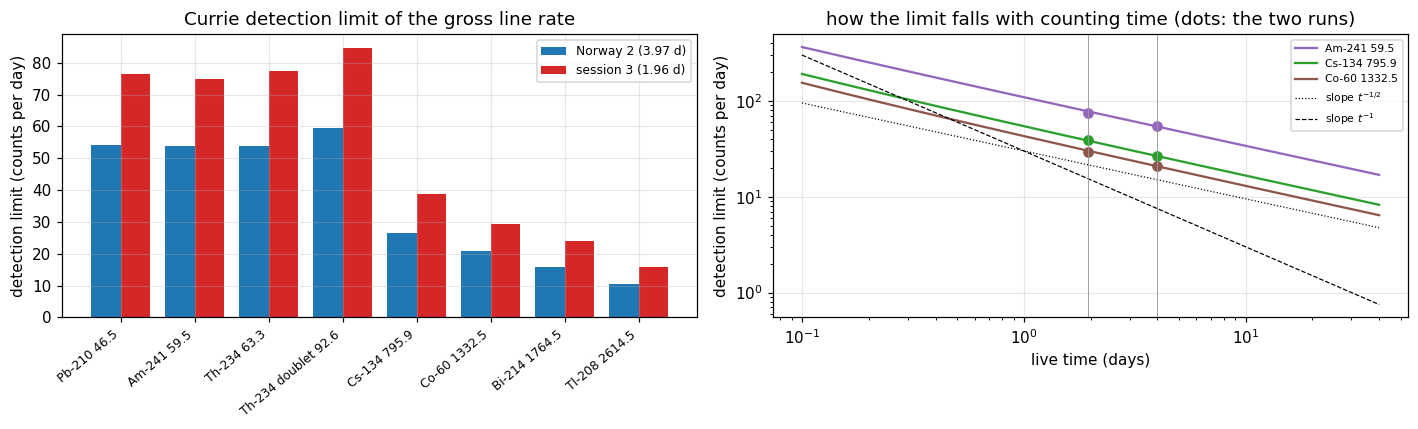

In [14]:
LIMIT_LINES = ["Pb-210 46.5", "Am-241 59.5", "Th-234 63.3", "Th-234 doublet 92.6", "Cs-134 795.9", "Co-60 1332.5",
               "Bi-214 1764.5", "Tl-208 2614.5"]


def currie(k, line):
    # Currie decision threshold and detection limit for one line in spectrum k
    g, cal, s = gross[k].loc[line], cals[k], specs[k]
    x_e = float(cal.channel(g.E))
    fw = G.fwhm_model(g.E, *WT) / float(cal.gain(x_e))                 # FWHM in channels
    sig = g.sigma_ch
    beta = TAU * sig
    f = G.emg_window_fraction(sig, beta, 1.25 * fw)                    # fraction of the peak within mode +/- 1.25 FWHM
    B = max(g.cont_per_ch, 0.0) * 2.5 * fw
    L_C, L_D = 2.33 * np.sqrt(B), 2.71 + 4.65 * np.sqrt(B)
    return dict(B=B, f=f, L_C=L_C, L_D=L_D, LD_cpd=86400 * L_D / (f * s.live), b_per_day=86400 * B / s.live)


rows = []
for line in LIMIT_LINES:
    co, cn = currie(TWIN, line), currie(NEW_RUN, line)
    pred = (2.71 + 4.65 * np.sqrt(co["b_per_day"] * T_NEW / 86400)) / (T_NEW / 86400) / \
           ((2.71 + 4.65 * np.sqrt(co["b_per_day"] * T_OLD / 86400)) / (T_OLD / 86400))
    rows.append(dict(line=line, B_old=co["B"], B_new=cn["B"], f=cn["f"], LD_old_cpd=co["LD_cpd"], LD_new_cpd=cn["LD_cpd"],
                     ratio=cn["LD_cpd"] / co["LD_cpd"], ratio_pred_same_b=pred,
                     net_old_cpd=get(TWIN, line).net_cpd, net_new_cpd=get(NEW_RUN, line).net_cpd))
limits = pd.DataFrame(rows)
table(limits, 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
x = np.arange(len(limits))
ax.bar(x - 0.2, limits.LD_old_cpd, 0.4, color="tab:blue", label=f"{TWIN} ({T_OLD / 86400:.2f} d)")
ax.bar(x + 0.2, limits.LD_new_cpd, 0.4, color="tab:red", label=f"{NEW_RUN} ({T_NEW / 86400:.2f} d)")
ax.set(xticks=x, ylabel="detection limit (counts per day)", title="Currie detection limit of the gross line rate")
ax.set_xticklabels(limits.line, rotation=40, ha="right", fontsize=8)
ax.legend(fontsize=8)
ax = axes[1]
tt = np.geomspace(0.1, 40, 200)
for line, col in (("Am-241 59.5", "tab:purple"), ("Cs-134 795.9", "tab:green"), ("Co-60 1332.5", "tab:brown")):
    bd = currie(TWIN, line)["b_per_day"]
    f = currie(TWIN, line)["f"]
    ax.loglog(tt, (2.71 + 4.65 * np.sqrt(bd * tt)) / (f * tt), color=col, label=line)
    ax.plot([T_OLD / 86400, T_NEW / 86400], [currie(TWIN, line)["LD_cpd"], currie(NEW_RUN, line)["LD_cpd"]], "o", color=col)
ax.loglog(tt, 30 / np.sqrt(tt), "k:", lw=0.8, label=r"slope $t^{-1/2}$")
ax.loglog(tt, 30 / tt, "k--", lw=0.8, label=r"slope $t^{-1}$")
for T in (T_NEW, T_OLD):
    ax.axvline(T / 86400, color="0.6", lw=0.6)
ax.set(xlabel="live time (days)", ylabel="detection limit (counts per day)",
       title="how the limit falls with counting time (dots: the two runs)")
ax.legend(fontsize=7)
fig.tight_layout(); save(fig, "detection_limits"); plt.show()

### Detection limits rise by about 1.4
None of the man-made lines that would point to a recent reactor release or to plutonium fallout is detected in either run (Am-241, Cs-134 and Co-60 all have $|z| < 1$). In Norway 2 the smallest detectable gross rates are 55 counts per day at 59.5 keV and 27 and 21 counts per day for Cs-134 and Co-60. In the new run they are 76, 39 and 30 counts per day, 1.39 to 1.52 times higher, as predicted (1.43 to 1.47). Even in two days every ROI holds at least 36 continuum counts, so the $\sqrt B$ term dominates and the limits scale as $1/\sqrt t$ rather than $1/t$.

The right panel shows what this means for planning. To halve a detection limit one must count four times longer, so pushing the Am-241 limit from 76 to 38 counts per day would need about 8 days on the same sample. The only other lever is the continuum itself, since $L_D \propto \sqrt b$ (better shielding, or a narrower ROI through better resolution). These are limits on count rates. The detector's efficiency at 59.5 keV is strongly suppressed (session 2 found $\varepsilon(59.5)/\varepsilon(239) < 0.42$), so the corresponding Am-241 activity limit is weaker than the rate alone suggests.

## B5. Calibration and resolution: precision against accuracy

### Why
The energy scale and the resolution are properties of the detector, so their true values do not depend on the counting time. What can change is how well we determine them, and here the distinction between precision and accuracy becomes concrete. Each calibration point has a statistical error (the peak position) and a systematic one (the ADC's non-linearity, the zigzag of about 80 to 100 eV found in session 2). Only the first shrinks with counting time.

### What we compare
* How many of the 13 reference lines pass the selection, and whether the F-test still sees the quadratic term.
* The statistical error of the line positions (in eV), the fitted per-line systematic, and the statistical uncertainty of the calibration curve at a few energies.
* The total uncertainty of an energy measured with the calibration, $s_E^2 = s_\text{stat}^2 + s_\text{cal}^2 + s_\text{sys}^2$, for a line that was not in the fit (Cs-137 at 661.657 keV), and how far it lands from the ENSDF value.
* The FWHM of the K-40 line, the best measured width in both runs.

### Expectation
Statistical parts grow by 1.43. The systematic floor is a property of the ADC, so its true size is the same, but its estimate from only 7 to 9 degrees of freedom is itself uncertain by roughly $1/\sqrt{2\nu} \approx 25\,\%$. Because the floor dominates the energy uncertainty of strong lines, the accuracy of energies should hardly suffer from the shorter run.

In [15]:
def cal_quality(k):
    c, t = calib[k], lines[k]
    u = t[t.used]
    cs = gross[k].loc["Cs-137 661.7"]
    x_cs = cals[k].channel(cs.E_fit)
    s_stat_cs = float(cals[k].gain(x_cs)) * float(fit_cs[k]["sposition"])
    s_tot_cs = np.sqrt(s_stat_cs**2 + float(cals[k].sigma(x_cs))**2 + cals[k].sys**2)
    k40 = t.set_index("E_ref").loc[1460.820]
    gk = float(cals[k].gain(k40.position))
    return {"lines used (of 13)": int(t.used.sum()), "F-test p": c["pF"], "adopted": c["how"],
            "median position error (eV)": 1000 * float(np.median(u.sE_stat)),
            "per-line systematic (eV)": 1000 * cals[k].sys,
            "cal. stat. error at 662 keV (eV)": 1000 * float(cals[k].sigma(x_cs)),
            "rms residual of used lines (eV)": 1000 * float(np.sqrt(np.mean(u.resid_keV**2))),
            "Cs-137 energy - ENSDF (eV)": 1000 * (cs.E_fit - 661.657),
            "Cs-137 statistical error (eV)": 1000 * s_stat_cs, "Cs-137 total error (eV)": 1000 * s_tot_cs,
            "K-40 FWHM (keV)": k40.fwhm_ch * gk, "K-40 FWHM error (keV)": k40.sfwhm_ch * gk}


fit_cs = {k: G.fit_line_at(specs[k], cals[k], 661.657, sigma_keV, TAU)[0] for k in (TWIN, NEW_RUN)}
cq = pd.DataFrame({TWIN: cal_quality(TWIN), NEW_RUN: cal_quality(NEW_RUN)})
cq["new / old"] = [n / o if isinstance(o, (int, float, np.floating)) and o != 0 else "" for o, n in zip(cq[TWIN], cq[NEW_RUN])]
with pd.option_context("display.float_format", "{:.4g}".format):
    print(cq.to_string())
kq = cq.loc[["K-40 FWHM (keV)", "K-40 FWHM error (keV)"]]
dF = kq.loc["K-40 FWHM (keV)", NEW_RUN] - kq.loc["K-40 FWHM (keV)", TWIN]
sF = np.hypot(kq.loc["K-40 FWHM error (keV)", NEW_RUN], kq.loc["K-40 FWHM error (keV)", TWIN])
print(f"\nK-40 FWHM new - old = {1000 * dF:.0f} +- {1000 * sF:.0f} eV ({dF / sF:.1f} sigma)")

                                   Norway 2  session 3 new / old
lines used (of 13)                       12         10    0.8333
F-test p                          0.0001159   0.003287     28.35
adopted                           quadratic  quadratic          
median position error (eV)            37.42       44.1     1.178
per-line systematic (eV)              78.92      129.8     1.645
cal. stat. error at 662 keV (eV)      30.35      51.21     1.687
rms residual of used lines (eV)       89.14      122.9     1.379
Cs-137 energy - ENSDF (eV)            83.21      112.7     1.354
Cs-137 statistical error (eV)         35.82      54.31     1.516
Cs-137 total error (eV)               91.83      149.7     1.631
K-40 FWHM (keV)                       1.838      1.978     1.076
K-40 FWHM error (keV)               0.04212    0.06353     1.508

K-40 FWHM new - old = 140 +- 76 eV (1.8 sigma)


### Precision suffers, accuracy hardly
The calibration of the new run rests on fewer lines (10 against 12). Its median position error grows only by 1.18, less than 1.43, because the lines that dropped out were the weakest ones with the largest errors. The statistical error of the calibration curve at 662 keV grows from 30 to 51 eV, a factor of 1.69, because the larger fitted systematic and the missing lines both widen it.

The accuracy of energies hardly suffers. Cs-137 is not one of the calibration lines, so it is an independent test. The new run puts it 113 eV above the ENSDF energy of 661.657 keV with a total uncertainty of 150 eV, and Norway 2 puts it 83 eV above with 92 eV. Both are consistent with the true energy and with each other, and their common offset is what a fixed non-linearity of the ADC near 662 keV would produce (the noise-free model of Section B6 gives +84 eV). So in both runs the accuracy of an energy is limited mainly by the ADC zigzag, and the shorter run adds about 54 eV of statistical error in quadrature. For identifying lines this makes no practical difference.

The K-40 width is 1.98 keV in the new run against 1.84 keV in Norway 2, a difference of $0.14 \pm 0.08$ keV (1.8σ). Resolution belongs to the detector, so this should be a fluctuation, and Section B6 tests that against simulated runs.

## B6. Hundreds of simulated runs: separating counting time from everything else

### Why simulate
Sections B2 to B5 compare one real two-day run with one real four-day run. Any single difference between them mixes three causes, namely the counting time, the random luck of each run, and anything else that changed between the runs (radon, gain, cosmic rays). With only one pair of runs we cannot tell these apart. A simulation can, because it keeps everything fixed except what we choose to vary.

### The truth of the simulation, and a trap to avoid
The obvious idea is to draw new spectra directly from the measured Norway 2 spectrum, $n_i^* \sim \text{Poisson}(n_i)$. This is wrong, and instructively so. The measured $n_i$ already scatter around the true mean $\lambda_i$ with variance $\lambda_i$, and drawing from them adds a second, independent scatter of the same size, so the copies have variance $2\lambda_i$ about the truth. Scaled to two days, $n_i^* \sim \text{Poisson}(p\,n_i)$ with $p = t_\text{new}/t_\text{old}$, the variance is $p\lambda_i + p^2\lambda_i = 1.49\,p\lambda_i$. Every simulated run would be noisier than any real run could be, the fits would look worse than they are (we first tried this, and the simulated four-day spectra failed the $p > 10^{-4}$ fit-quality cut that every real spectrum passes), and the comparison of the two times would be distorted, because the extra noise is not the same fraction for both.

So we first build a **noise-free model** $\lambda_i$ of the Norway 2 spectrum and use that as the truth.
* **Peaks.** Every peak we have fitted in Norway 2 (the 13 calibration lines with their neighbours and free widths, the other lines of Section A5 with the fixed shape, and every remaining peak of the inventory such as the X-rays and the broadened 511 keV line) is added as its exact fitted EMG, integrated over each channel.
* **Continuum.** The channels within about 3.5 FWHM of any peak are removed, the rest is smoothed with a Gaussian kernel of 6 channels (1 keV) by normalised convolution, which ignores the removed channels, and the gaps under the peaks are bridged linearly.
* **Check.** If $\lambda$ is a good model, the measured spectrum is one Poisson realisation of it, and $\sum(n_i - \lambda_i)^2/\lambda_i$ per channel must be close to 1. It comes out slightly below 1, because the smoothing kernel reuses a few per cent of each channel's own count.

### Method
* **Two-day runs.** $n_i^* \sim \text{Poisson}(\lambda_i\,t_\text{new}/t_\text{old})$, live time $t_\text{new}$.
* **Four-day runs.** $n_i^* \sim \text{Poisson}(\lambda_i)$, live time $t_\text{old}$, as a control.

Every simulated spectrum goes through the full Part A pipeline (line fits, line selection, F-test, calibration, gross rates of every line, peak search), so the simulation tests the method as used, not an idealised formula. The targets are the results of the same pipeline applied to the noise-free model itself. The rough calibration that starts the line fits is the Norway 2 calibration, to save the time of pattern matching in each run (Part A showed that pattern matching works on the real two-day run). The live time is the only thing that differs between the two sets.

### What we read from the simulations
1. **Precision.** The spread of each rate over the two-day runs against the four-day runs. It should be 1.43 times larger.
2. **Honest errors.** The pull $(R^* - R_\text{true})/\sigma^*$ should have a standard deviation of 1. If it does, the error bars quoted from a single two-day run can be trusted.
3. **Accuracy.** The average of $R^*$ against $R_\text{true}$. For strong lines it should agree. For lines with little or no signal the fitted area is not allowed below zero, so we expect a positive bias that grows as the time shrinks.
4. **Detection probability.** How often each line exceeds $z = 3$ after background subtraction.
5. **Calibration and inventory.** How the number of usable calibration lines, the F-test, the fitted systematic, the K-40 width and the number of peaks found are distributed. The real new run is then placed in these distributions. If it is typical of a two-day run of Norway 2, its differences from the four-day run are explained by counting time alone. Peaks too weak for any of our fits are smoothed into the model continuum, so the simulated runs may find slightly fewer peaks than real ones.

In [16]:
import dataclasses
import time
from scipy.ndimage import gaussian_filter1d

parent, pcal = specs[TWIN], cals[TWIN]


def smooth_truth(s, cal, calib_fits, inventory):
    # noise-free model of spectrum s: every fitted peak (exact EMG) plus a smoothed continuum, in counts
    x = s.channels
    peaks = []
    for fit in calib_fits.values():                              # reference lines and neighbours, widths free
        th = fit["theta"]
        peaks += [(th[6 + 2 * k], th[7 + 2 * k], th[3], th[4]) for k in range(fit["n_peaks"])]
    have = lambda E: any(abs(float(cal.energy(m)) - E) < 1.0 for _, m, _, _ in peaks)
    for name, E, nb in SAMPLE_LINES:                             # the other lines of Section A5, fixed shape
        _, fit = G.fit_line_at(s, cal, E, sigma_keV, TAU, neighbours=nb)
        th = fit["theta"]
        for k in range(fit["n_peaks"]):
            if not have(float(cal.energy(th[7 + 2 * k]))):
                peaks.append((th[6 + 2 * k], th[7 + 2 * k], th[3], th[4]))
    for r in inventory.itertuples():                             # anything else the search found
        if not have(r.E_keV):
            sg = float(sigma_keV(r.E_keV) / cal.gain(r.position)) * (r.width_ratio if np.isfinite(r.width_ratio) else 1.0)
            peaks.append((r.area, r.position - G.emg_mode(0.0, sg, TAU * sg), sg, TAU * sg))
    peaks = [pk for pk in peaks if pk[0] > 0]
    near = np.zeros(s.n, bool)
    for A, mu, sg, b in peaks:
        near |= (x > mu - 8 * sg - 5 * b) & (x < mu + 8 * sg)
    w = (~near).astype(float)
    num, den = gaussian_filter1d(s.counts * w, 6.0), gaussian_filter1d(w, 6.0)
    ok = den > 0.5
    lam = np.interp(x, x[ok], num[ok] / den[ok])
    for A, mu, sg, b in peaks:
        lam = lam + A * G.peak_in_bins(x, mu, sg, b)
    return lam, len(peaks)


lam, n_model_peaks = smooth_truth(parent, pcal, calib[TWIN]["fits"], inv[TWIN])
print(f"noise-free model of {TWIN}: {n_model_peaks} peaks, total {lam.sum():.0f} counts (measured {parent.counts.sum()})")
for lo, hi in [(38, 42), (42, 70), (70, 95), (95, 200), (200, 500), (500, 1500), (1500, 2700)]:
    i = np.arange(int(pcal.channel(lo)), int(pcal.channel(hi)))
    d = np.sum((parent.counts[i] - lam[i])**2 / lam[i]) / len(i)
    print(f"   {lo:4d}-{hi:4d} keV: sum (n - lambda)^2 / lambda per channel = {d:.3f}, "
          f"measured / model counts = {parent.counts[i].sum() / lam[i].sum():.3f}")
print(f"(1 for a perfect model, about {1 - 1 / (2 * np.sqrt(np.pi) * 6):.2f} expected after smoothing)")
i = np.arange(int(pcal.channel(95)), int(pcal.channel(2700)))
d_naive = np.sum((parent.counts[i] - lam[i])**2 + parent.counts[i]) / np.sum(lam[i])
print(f"95-2700 keV: variance about the truth of a copy drawn from the MEASURED spectrum instead: {d_naive:.2f} x Poisson")

noise-free model of Norway 2: 30 peaks, total 778639 counts (measured 785110)
     38-  42 keV: sum (n - lambda)^2 / lambda per channel = 2.294, measured / model counts = 0.950
     42-  70 keV: sum (n - lambda)^2 / lambda per channel = 0.980, measured / model counts = 0.995
     70-  95 keV: sum (n - lambda)^2 / lambda per channel = 4.197, measured / model counts = 1.084
     95- 200 keV: sum (n - lambda)^2 / lambda per channel = 0.940, measured / model counts = 1.000
    200- 500 keV: sum (n - lambda)^2 / lambda per channel = 0.930, measured / model counts = 1.002
    500-1500 keV: sum (n - lambda)^2 / lambda per channel = 0.970, measured / model counts = 1.012
   1500-2700 keV: sum (n - lambda)^2 / lambda per channel = 0.925, measured / model counts = 0.998
(1 for a perfect model, about 0.95 expected after smoothing)
95-2700 keV: variance about the truth of a copy drawn from the MEASURED spectrum instead: 1.96 x Poisson


In [17]:
def run_once(s):
    # the Part A pipeline on one spectrum: calibration, gross rates of every line, peak search
    t, _ = G.fit_lines(s, pcal, tail_ratio=TAU, step=STEP)
    t["used"] = G.select_lines(t)
    u = t[t.used]
    lin = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=1, scale_by_chi2=False)
    quad = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, scale_by_chi2=False)
    F, pF = G.f_test(lin, quad) if quad.ndf > 0 and quad.chi2 > 0 else (np.nan, 0.0)
    if pF < 0.01:
        cal = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, sys_keV="auto")
    else:
        cal = G.fit_calibration_borrowed_shape(u.position, u.sposition, u.E_ref, u.sE_ref, cals[REFERENCE])
    out = dict(n_used=int(t.used.sum()), pF=pF, quadratic=pF < 0.01, sys_eV=1000 * cal.sys,
               cal_err_662_eV=1000 * float(cal.sigma(cal.channel(661.657))))
    k40 = t.set_index("E_ref").loc[1460.820]
    out["K40_fwhm_keV"] = k40.fwhm_ch * float(cal.gain(k40.position))
    cands, _, _ = G.calibrated_search(s.counts, cal, sigma_keV)
    out["n_peaks"] = len(cands)
    for name, E, nb in SAMPLE_LINES:
        p, _ = G.fit_line_at(s, cal, E, sigma_keV, TAU, neighbours=nb)
        line = f"{name} {E:.1f}"
        out[f"R|{line}"], out[f"sR|{line}"] = 86400 * p["rate"], 86400 * p["s_rate"]
        if line == "Cs-137 661.7":
            out["Cs137_dE_eV"] = 1000 * (p["E_fit"] - 661.657)
    return out


target = run_once(dataclasses.replace(parent, counts=lam))       # the pipeline applied to the noise-free truth
rng = np.random.default_rng(SEED)
bk = gross[BACKGROUND]
t0 = time.time()
sims = {}
for label, T in (("2 days", T_NEW), ("4 days", T_OLD)):
    rows = []
    for _ in range(N_SIM):
        s = dataclasses.replace(parent, counts=rng.poisson(lam * (T / parent.live)), live=T, real=T * parent.real / parent.live)
        rows.append(run_once(s))
    sims[label] = pd.DataFrame(rows)
print(f"{2 * N_SIM} simulated runs analysed in {time.time() - t0:.0f} s")
real = {k: run_once(specs[k]) for k in (TWIN, NEW_RUN)}          # the real runs through the same function

500 simulated runs analysed in 82 s


In [18]:
rows = []
for line in ORDER:
    R_true = target[f"R|{line}"]
    r = {"line": line, "true_cpd": R_true}
    for label, df in sims.items():
        R, sR = df[f"R|{line}"], df[f"sR|{line}"]
        zz = (R - 86400 * bk.rate[line]) / np.hypot(sR, 86400 * bk.s_rate[line])
        tag = label.split()[0] + "d"
        r[f"sd {tag}"] = R.std(ddof=1)
        r[f"bias {tag} (sd units)"] = (R.mean() - R_true) / (R.std(ddof=1) / np.sqrt(len(R)))
        r[f"bias {tag} (cpd)"] = R.mean() - R_true
        r[f"pull sd {tag}"] = ((R - R_true) / sR).std(ddof=1)
        r[f"P(z>3) {tag}"] = np.mean(zz > 3)
    r["sd ratio 2d/4d"] = r["sd 2d"] / r["sd 4d"]
    rows.append(r)
simtab = pd.DataFrame(rows)
cols = ["line", "true_cpd", "sd 4d", "sd 2d", "sd ratio 2d/4d", "pull sd 4d", "pull sd 2d", "bias 4d (cpd)",
        "bias 2d (cpd)", "bias 2d (sd units)", "P(z>3) 4d", "P(z>3) 2d"]
table(simtab[cols], 2)
print(f"\nmean sd ratio 2 days / 4 days over all lines: {simtab['sd ratio 2d/4d'].mean():.3f} "
      f"(prediction {np.sqrt(T_OLD / T_NEW):.3f}); mean pull sd {simtab['pull sd 2d'].mean():.3f} (2 d), "
      f"{simtab['pull sd 4d'].mean():.3f} (4 d)")

summ = []
for q, lab in (("n_used", "calibration lines used"), ("quadratic", "F-test finds the curvature (p < 0.01)"),
               ("sys_eV", "per-line systematic (eV)"), ("cal_err_662_eV", "calibration error at 662 keV (eV)"),
               ("Cs137_dE_eV", "Cs-137 energy - ENSDF (eV)"), ("K40_fwhm_keV", "K-40 FWHM (keV)"),
               ("n_peaks", "peaks with S > 5")):
    d2, d4 = sims["2 days"][q].astype(float), sims["4 days"][q].astype(float)
    rv = float(real[NEW_RUN][q])
    summ.append({"quantity": lab, "truth": float(target[q]) if q != "n_peaks" else np.nan, "4 d mean": d4.mean(), "4 d sd": d4.std(ddof=1), "2 d mean": d2.mean(),
                 "2 d sd": d2.std(ddof=1), f"real {TWIN}": float(real[TWIN][q]), "real new": rv,
                 "percentile of real new in 2 d sims": 100 * (np.mean(d2 < rv) + 0.5 * np.mean(d2 == rv))})
sim_summary = pd.DataFrame(summ)
print()
table(sim_summary, 3)

                line  true_cpd  sd 4d  sd 2d  sd ratio 2d/4d  pull sd 4d  pull sd 2d  bias 4d (cpd)  bias 2d (cpd)  bias 2d (sd units)  P(z>3) 4d  P(z>3) 2d
         Pb-210 46.5     12.73   9.68  12.12            1.25        0.85        0.75           3.53           7.73               10.09       0.00       0.00
         Am-241 59.5     15.55   9.23  12.66            1.37        0.85        0.80           5.07           8.32               10.39       0.00       0.00
         Th-234 63.3     22.14   9.84  13.53            1.37        0.90        0.85           2.16           5.35                6.25       0.00       0.00
 Th-234 doublet 92.6     54.33  11.62  17.71            1.52        0.99        1.05           0.92           3.80                3.40       0.07       0.06
Ra-226 + U-235 186.0     91.51  14.55  19.59            1.35        1.02        0.96          -0.28           2.49                2.01       0.78       0.51
        Pb-212 238.6    452.91  16.48  23.58            1.

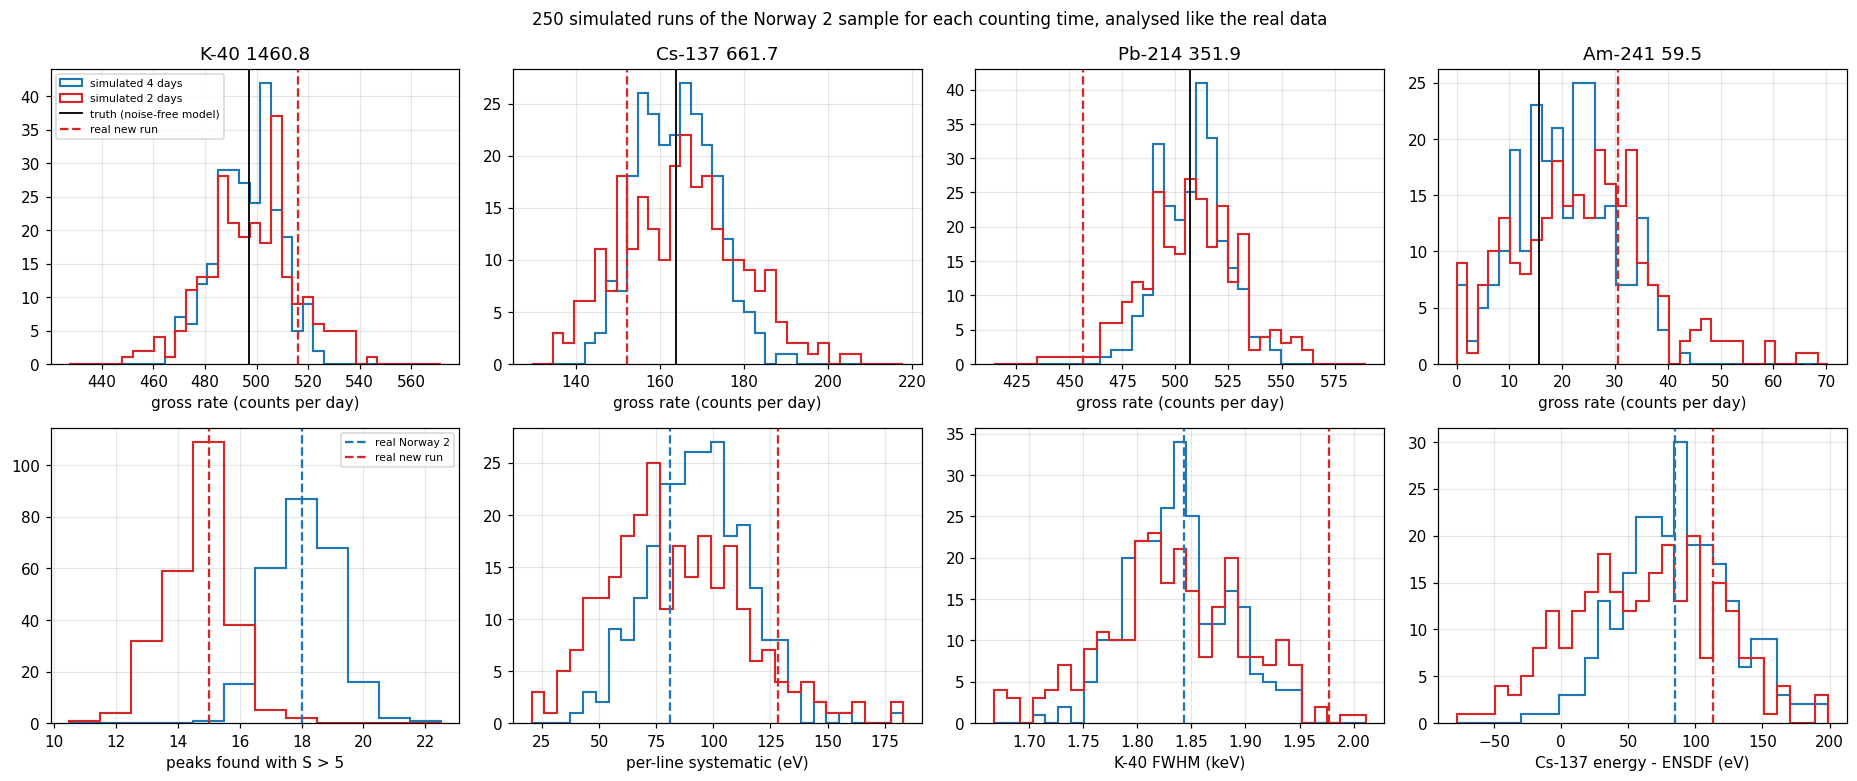

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2))
for ax, line in zip(axes[0], ["K-40 1460.8", "Cs-137 661.7", "Pb-214 351.9", "Am-241 59.5"]):
    lo = min(sims["2 days"][f"R|{line}"].min(), real[NEW_RUN][f"R|{line}"]) * 0.95
    hi = max(sims["2 days"][f"R|{line}"].max(), real[NEW_RUN][f"R|{line}"]) * 1.05
    bins = np.linspace(0 if line == "Am-241 59.5" else lo, hi, 36)     # Am-241: rates pile up at the zero bound
    for label, col in (("4 days", "tab:blue"), ("2 days", "tab:red")):
        ax.hist(sims[label][f"R|{line}"], bins=bins, histtype="step", lw=1.4, color=col, label=f"simulated {label}")
    ax.axvline(target[f"R|{line}"], color="k", lw=1.2, label="truth (noise-free model)")
    ax.axvline(real[NEW_RUN][f"R|{line}"], color="tab:red", lw=1.5, ls="--", label="real new run")
    ax.set(xlabel="gross rate (counts per day)", title=line)
axes[0, 0].legend(fontsize=7)
for ax, (q, lab) in zip(axes[1], [("n_peaks", "peaks found with S > 5"), ("sys_eV", "per-line systematic (eV)"),
                                  ("K40_fwhm_keV", "K-40 FWHM (keV)"), ("Cs137_dE_eV", "Cs-137 energy - ENSDF (eV)")]):
    allv = pd.concat([sims["2 days"][q], sims["4 days"][q]]).astype(float)
    bins = np.arange(allv.min() - 0.5, allv.max() + 1.5) if q == "n_peaks" else np.linspace(allv.min(), allv.max(), 30)
    for label, col in (("4 days", "tab:blue"), ("2 days", "tab:red")):
        ax.hist(sims[label][q].astype(float), bins=bins, histtype="step", lw=1.4, color=col)
    ax.axvline(real[TWIN][q], color="tab:blue", lw=1.5, ls="--", label=f"real {TWIN}")
    ax.axvline(real[NEW_RUN][q], color="tab:red", lw=1.5, ls="--", label="real new run")
    ax.set(xlabel=lab)
axes[1, 0].legend(fontsize=7)
fig.suptitle(f"{N_SIM} simulated runs of the Norway 2 sample for each counting time, analysed like the real data", fontsize=11)
fig.tight_layout(); save(fig, "simulated_runs"); plt.show()

### What the simulations show
**The noise-free model is a fair truth.** Above 95 keV the measured Norway 2 spectrum scatters about the model by 0.93 to 0.97 times the Poisson variance, close to the 0.95 expected after smoothing. The model misses about 8 % of the counts in the 70 to 95 keV cluster of unresolved Pb and Bi X-ray lines and blurs the edge of the 36 keV step. Among our lines this affects only the continuum of the Th-234 doublet at 92.6 keV. A copy drawn from the measured spectrum instead would carry about twice the Poisson variance in the same test, which is the trap described above.

**Precision scales exactly as predicted.** Over the 19 lines the spread of the two-day rates is on average 1.422 times that of the four-day rates, against $\sqrt{2.03} = 1.425$. This is the cleanest confirmation of the $1/\sqrt t$ law in this notebook, because nothing but the counting time differs between the two sets.

**The quoted errors are honest.** For every line with a real signal the pull has a standard deviation between 0.90 and 1.11 in both sets, so the error bar from a single two-day run means what it says. Lines with little or no signal (Pb-210, Am-241, Th-234 at 63.3 keV, Co-60) have narrower pulls, 0.71 to 0.90, because their fitted areas pile up at the lower bound of zero.

**Accuracy is unchanged for real lines and worse for weak ones.** The strong lines are unbiased within about 1 % in both sets. For lines whose true rate is within one or two standard deviations of zero, the zero bound produces a positive bias. If the estimates scatter as a Gaussian of width $\sigma$ around a true value near zero, setting the negative ones to zero raises the average by up to $\sigma/\sqrt{2\pi} \approx 0.4\sigma$, and $\sigma$ grows as $1/\sqrt t$. The simulations show exactly this. The bias of Am-241 grows from +5.1 counts per day in four days to +8.3 in two, that of Co-60 from +2.4 to +4.2. Here counting less makes the result less accurate, not only less precise. For such lines the honest result is the Currie limit of Section B4, or a fit that allows negative areas.

**Detection becomes a coin toss near the threshold.** Ac-228 at 969.0 keV exceeds $z = 3$ in 54 % of four-day runs but only 26 % of two-day runs, Bi-214 at 1120.3 keV in 97 % against 64 %, the 186 keV Ra-226 + U-235 doublet in 78 % against 51 %, and Tl-208 at 2614.5 keV (after its large background is subtracted) in 40 % against 12 %.

**The calibration loses lines but not its accuracy.** Two-day runs use $10.2 \pm 0.5$ calibration lines against $12.0 \pm 0.7$, and the F-test still finds the curvature in 97 % of them. The statistical error of the calibration at 662 keV barely changes on average ($36 \pm 9$ against $35 \pm 7$ eV). The fitted systematic is chosen to make $\chi^2/\nu = 1$, so when the statistical errors of the points grow, less systematic is needed ($84 \pm 30$ against $94 \pm 22$ eV), and the total scatter that the curve must absorb, which is set by the ADC zigzag, stays the same. The Cs-137 energy offset averages +62 eV in two-day runs against +87 eV in four-day runs and +84 eV in the truth. This 22 eV shift is small but real, and it comes from the line selection. Losing the weakest lines changes which points of the zigzag the polynomial follows.

**Where the real new run sits.** For the number of calibration lines (39th percentile), the F-test and the number of peaks (60th percentile) the real run is a typical two-day run of Norway 2. Its fitted systematic (93rd percentile), its calibration error (95th) and its Cs-137 offset (80th) are on the high side but within the spread. Only the K-40 width is unusual, wider than 99 % of the simulated two-day runs. Its centroid also sat 0.09 keV (2.4σ) above Norway 2. A small gain change during the new run would widen and shift a line in this way, but it would affect the other strong lines in proportion to their energy, and Tl-208 at 2614.5 keV is neither shifted nor clearly wider. With seven quantities compared, one of them beyond the 99th percentile has about a 7 % chance by luck, so we record it as unexplained but not significant. It hardly matters for the rates. Refitting K-40 with a free width raises its rate by 1.8 %, about half of its 3.4 % statistical error.

## B7. Do the two real runs agree? Accuracy, and what else changed between them

### Why
B6 tells us how much a two-day run of Norway 2 scatters if nothing but the counting time is different. We can now ask whether the real new run is consistent with the real Norway 2 run, line by line and in the continuum. Agreement within statistics means the new result is as accurate as the old one, only less precise. A disagreement larger than statistics allows means something besides time changed between the runs, and that is a systematic effect which longer counting would not remove.

### Method
* **Lines.** For each line we form the pull of the gross rates, $(R_\text{new} - R_\text{old})/\sqrt{\sigma_\text{new}^2 + \sigma_\text{old}^2}$. Gross rates are used because the same background run would cancel in the difference of net rates, and including it would double-count its uncertainty. The lines are grouped as in Section A5 (the sample's own lines against the radon daughters), and $\chi^2 = \sum \text{pull}^2$ is tested for each group.
* **Continuum.** Counts in wide energy bands have tiny Poisson errors (a 300 keV band holds about $10^5$ counts, a 0.3 % error), so even small changes in the background show up. The band above 2650 keV, beyond every natural line, holds almost only cosmic-ray events, while the region from 200 to 500 keV contains the Compton continuum of the radon daughters. Comparing them tells us which source changed.

                line                    group  old_cpd  new_cpd  diff_cpd  s_diff_cpd  pull
         Pb-210 46.5           weak or absent    12.73    32.81     20.08       19.71  1.02
         Am-241 59.5           weak or absent    15.55    30.67     15.12       19.65  0.77
         Th-234 63.3           weak or absent    22.15    21.61     -0.53       18.90 -0.03
 Th-234 doublet 92.6           weak or absent    54.33    70.66     16.33       21.32  0.77
Ra-226 + U-235 186.0           weak or absent    91.51   113.47     21.96       24.81  0.89
        Pb-212 238.6 sample (K, Cs, Th chain)   450.39   458.80      8.41       29.18  0.29
        Pb-214 295.2          radon daughters   297.39   272.44    -24.95       24.13 -1.03
        Pb-214 351.9          radon daughters   507.38   456.42    -50.96       26.30 -1.94
        Tl-208 583.2 sample (K, Cs, Th chain)   133.74   118.88    -14.86       14.85 -1.00
        Bi-214 609.3          radon daughters   326.13   313.43    -12.70       

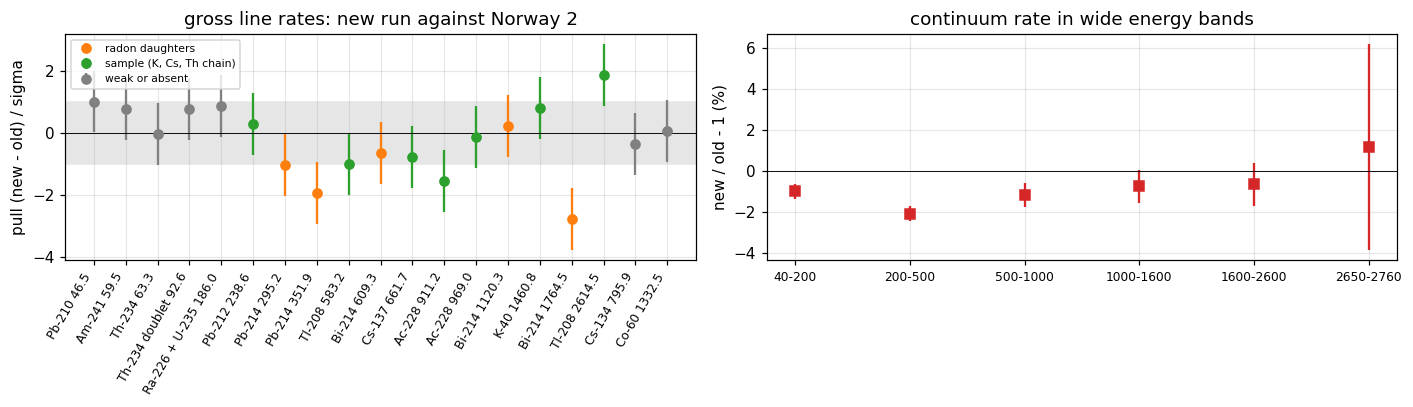

In [20]:
rows = []
for line in ORDER:
    go, gn = gross[TWIN].loc[line], gross[NEW_RUN].loc[line]
    d = 86400 * (gn.rate - go.rate)
    sd = 86400 * np.hypot(gn.s_rate, go.s_rate)
    rows.append(dict(line=line, group=GROUP.get(line, "weak or absent"), old_cpd=86400 * go.rate, new_cpd=86400 * gn.rate,
                     diff_cpd=d, s_diff_cpd=sd, pull=d / sd))
agree = pd.DataFrame(rows)
table(agree, 2)
print()
for grp, df in agree.groupby("group"):
    chi2 = float(np.sum(df.pull**2))
    print(f"{grp:26s}: chi2 = {chi2:5.1f} for {len(df)} lines, p = {stats.chi2.sf(chi2, len(df)):.3f}, "
          f"mean pull {df.pull.mean():+.2f} +- {1 / np.sqrt(len(df)):.2f}")

BAND_CHECK = [(40, 200), (200, 500), (500, 1000), (1000, 1600), (1600, 2600), (2650, 2760)]
rows = []
for lo, hi in BAND_CHECK:
    r = {"band (keV)": f"{lo}-{hi}"}
    vals = {k: G.window_rate(specs[k], cals[k], lo, hi) for k in (BACKGROUND, TWIN, NEW_RUN)}
    for k, (v, sv) in vals.items():
        r[f"{k} (cpd/keV)"] = 86400 * v
    (vo, so), (vn, sn) = vals[TWIN], vals[NEW_RUN]
    r["new/old - 1 (%)"] = 100 * (vn / vo - 1)
    r["error (%)"] = 100 * (vn / vo) * np.hypot(so / vo, sn / vn)
    r["z"] = r["new/old - 1 (%)"] / r["error (%)"]
    r["new - old as % of (old - bkg)"] = 100 * (vn - vo) / (vo - vals[BACKGROUND][0])
    rows.append(r)
bands = pd.DataFrame(rows)
print()
table(bands, 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
cols_g = {"sample (K, Cs, Th chain)": "tab:green", "radon daughters": "tab:orange", "weak or absent": "0.5"}
for grp, df in agree.groupby("group"):
    ax.errorbar(df.index, df.pull, yerr=1, fmt="o", color=cols_g[grp], label=grp)
ax.axhline(0, color="k", lw=0.6)
ax.axhspan(-1, 1, color="0.9")
ax.set(xticks=agree.index, ylabel="pull (new - old) / sigma", title="gross line rates: new run against Norway 2")
ax.set_xticklabels(agree.line, rotation=60, ha="right", fontsize=8)
ax.legend(fontsize=7)
ax = axes[1]
ax.errorbar(np.arange(len(bands)), bands["new/old - 1 (%)"], yerr=bands["error (%)"], fmt="s", color="tab:red")
ax.axhline(0, color="k", lw=0.6)
ax.set(xticks=np.arange(len(bands)), ylabel="new / old - 1 (%)", title="continuum rate in wide energy bands")
ax.set_xticklabels(bands["band (keV)"], fontsize=8)
fig.tight_layout(); save(fig, "agreement"); plt.show()

### The sample agrees, the radon does not
The sample's own lines agree between the runs ($\chi^2 = 8.2$ for 7 lines, $p = 0.31$, mean pull $-0.07 \pm 0.38$), and so do the weak or absent lines ($\chi^2 = 3.3$ for 7). The new run therefore measures the same activities as Norway 2. It is as accurate, only less precise.

The radon daughters do not agree. Four of the five radon lines are lower in the new run, with a mean pull of $-1.24 \pm 0.45$ and $\chi^2 = 13.0$ for 5 lines ($p = 0.024$). Bi-214 at 1764.5 keV (−2.8σ) and Pb-214 at 351.9 keV (−1.9σ) contribute most. The continuum shows the same thing more precisely. Between 200 and 500 keV, where the Compton continuum of the Pb-214 and Bi-214 lines is strongest, the new run is $2.1 \pm 0.4\,\%$ lower (5.6σ), and the 40 to 200 and 500 to 1000 keV bands are 1.0 and 1.2 % lower (2.6σ and 2.0σ). Above 2650 keV, where only cosmic-ray events remain, the runs agree ($+1 \pm 5\,\%$), and the sample's own lines agree, so as far as these data can tell neither the cosmic-ray flux nor the sample changed.

**Why.** The natural explanation is less radon in the air inside the shield during the new run. Rn-222 (half-life 3.8 days) seeps in from the laboratory air, its concentration follows ventilation, weather and atmospheric pressure, and its short-lived daughters Pb-214 and Bi-214 add lines and a Compton continuum to every spectrum in proportion to the radon present. The gross Pb-214 rate at 351.9 keV fell by $51 \pm 26$ counts per day, about 20 % of the 227 counts per day that the empty shield showed in the background run. Radon inside the pot could also change, but if the pot had been sealed shortly before session 2, its daughters would have grown towards equilibrium and been higher in the later run, not lower.

**Consequences.** This difference has nothing to do with counting time, and counting longer would not remove it. It is a systematic uncertainty of every radon-daughter rate, of the Ra-226/K-40 ratio in particular, and of the background subtraction, since the background run of 12 to 15 October had its own radon level. Here it is larger than the statistical error of the Pb-214 net rate in either run (21 and 26 counts per day). It can be reduced by flushing the shield with nitrogen boil-off gas, by measuring a background immediately before or after each sample, and by using the radon daughters only in a pot sealed for about three weeks.

## B8. The uncertainty budget: how long should one count?

### Why
B3 showed that the net-rate errors grow by less than the counting statistics of the sample alone predict, because part of the uncertainty is fixed. For the numbers we actually report, the activity ratios of Section A7, even more parts are fixed. Splitting the final uncertainty into its sources answers the practical question behind this whole comparison, namely when counting the sample for longer stops paying off and what one should measure longer instead.

### Method
An activity ratio is a function of eight independent inputs, the gross rates of line X and of K-40 in the sample run, the same two in the IAEA-385 run, the two background-run rates, and the two certificate activities,
$$ q = \frac{(G^s_X - B_X)/(G^s_K - B_K)}{(G^r_X - B_X)/(G^r_K - B_K)}\cdot\frac{A_X}{A_K}. $$
The background rates appear in both the sample and the reference terms, so they are correlated, and the correct way to propagate them is through the partial derivatives of $q$ with respect to each independent input,
$$ \sigma_q^2 = \sum_j \left(\frac{\partial q}{\partial x_j}\right)^2 \sigma_{x_j}^2 . $$
We group the terms into four sources (sample run, background run, IAEA-385 run, certificate). Only the sample term scales with the sample's counting time, as $1/t$ in variance, so we can predict the total uncertainty for any sample counting time from the Norway 2 run, and compare that prediction with what the real new run gives.

### The classical rule for dividing time
If a fixed total time $T$ is shared between a sample run (gross rate $R_s$) and a background run (rate $R_b$) for one line, the net-rate error is smallest when $t_s/t_b = \sqrt{R_s/R_b}$. This follows from minimising $R_s/t_s + R_b/t_b$ with $t_s + t_b = T$. We print it for the main lines as a guide for planning later sessions.

               ratio       run  value  rel error (%)  sample share of variance (%)  IAEA_385_run share of variance (%)  background_run share of variance (%)  certificate share of variance (%)
Cs-137/K-40 (Cs-137)  Norway 2 0.0277         8.6995                       60.2186                             20.3239                                9.9737                             9.4838
Cs-137/K-40 (Cs-137) session 3 0.0243        11.4742                       76.0583                             11.6830                                6.8070                             5.4517
Th-232/K-40 (Pb-212)  Norway 2 0.0699         7.2698                       56.9696                             21.6028                                8.8365                            12.5911
Th-232/K-40 (Pb-212) session 3 0.0678         8.9435                       72.3028                             14.2736                                5.1043                             8.3193
Ra-226/K-40 (Pb-214)  Norway 2 0.0739   

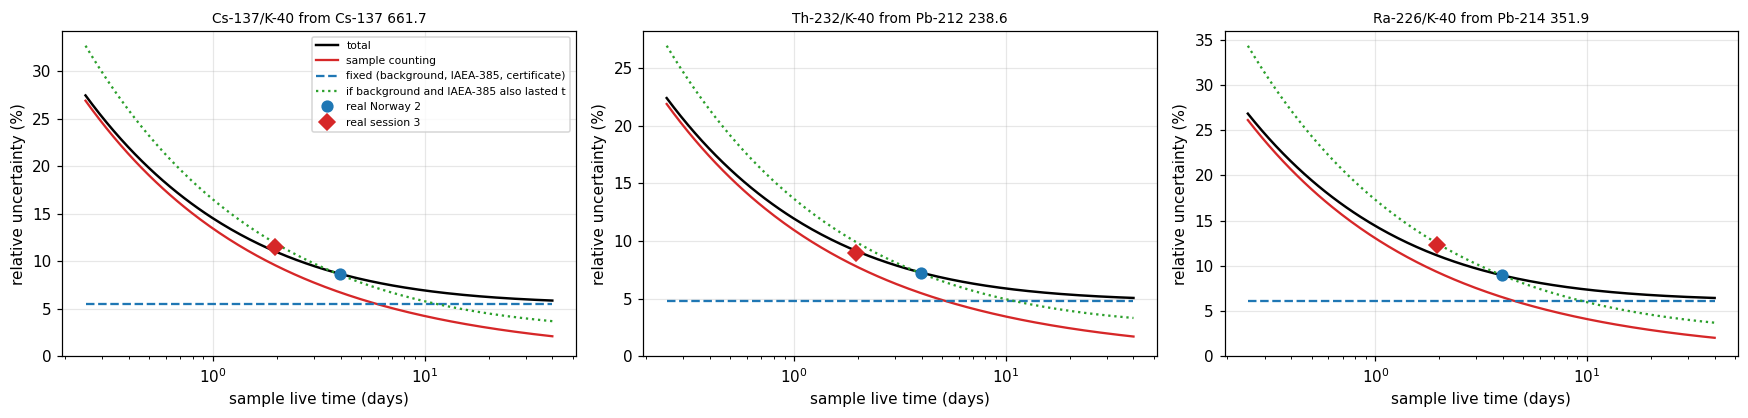

time split that minimises the net-rate error for a fixed total time, t_sample / t_background = sqrt(R_s / R_b):
   K-40 1460.8   : gross  498.4 cpd, background  159.9 cpd, ratio  1.77
   Cs-137 661.7  : gross  163.8 cpd, background    8.5 cpd, ratio  4.38
   Pb-212 238.6  : gross  450.4 cpd, background   45.1 cpd, ratio  3.16
   Pb-214 351.9  : gross  507.4 cpd, background  227.0 cpd, ratio  1.50
   Bi-214 609.3  : gross  326.1 cpd, background  170.1 cpd, ratio  1.38


In [21]:
def budget(sample, line, act):
    # variance contributions to the activity ratio X/K-40 from the four independent sources
    x = np.array([gross[sample].rate[line], gross[sample].rate["K-40 1460.8"], gross[REFERENCE].rate[line],
                  gross[REFERENCE].rate["K-40 1460.8"], gross[BACKGROUND].rate[line], gross[BACKGROUND].rate["K-40 1460.8"],
                  A_ref[act][0], A_ref["K-40"][0]])
    sx = np.array([gross[sample].s_rate[line], gross[sample].s_rate["K-40 1460.8"], gross[REFERENCE].s_rate[line],
                   gross[REFERENCE].s_rate["K-40 1460.8"], gross[BACKGROUND].s_rate[line],
                   gross[BACKGROUND].s_rate["K-40 1460.8"], A_ref[act][1], A_ref["K-40"][1]])
    q = lambda v: ((v[0] - v[4]) / (v[1] - v[5])) / ((v[2] - v[4]) / (v[3] - v[5])) * v[6] / v[7]
    grad = np.zeros(8)
    for j in range(8):
        h = 1e-6 * abs(x[j])
        xp, xm = x.copy(), x.copy()
        xp[j] += h
        xm[j] -= h
        grad[j] = (q(xp) - q(xm)) / (2 * h)
    v = (grad * sx)**2
    return q(x), dict(sample=v[0] + v[1], IAEA_385_run=v[2] + v[3], background_run=v[4] + v[5], certificate=v[6] + v[7])


rows = []
for line, act in [("Cs-137 661.7", "Cs-137"), ("Pb-212 238.6", "Th-232"), ("Pb-214 351.9", "Ra-226")]:
    for k in (TWIN, NEW_RUN):
        q, v = budget(k, line, act)
        tot = sum(v.values())
        rows.append({"ratio": f"{act}/K-40 ({line.split()[0]})", "run": k, "value": q, "rel error (%)": 100 * np.sqrt(tot) / q,
                     **{f"{s} share of variance (%)": 100 * vv / tot for s, vv in v.items()}})
bud = pd.DataFrame(rows)
table(bud, 4)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
tt = np.geomspace(0.25, 40, 200)
for ax, (line, act) in zip(axes, [("Cs-137 661.7", "Cs-137"), ("Pb-212 238.6", "Th-232"), ("Pb-214 351.9", "Ra-226")]):
    q, v = budget(TWIN, line, act)
    fixed = v["IAEA_385_run"] + v["background_run"] + v["certificate"]
    samp = v["sample"] * (T_OLD / 86400) / tt
    ax.plot(tt, 100 * np.sqrt(samp + fixed) / q, color="k", lw=1.6, label="total")
    ax.plot(tt, 100 * np.sqrt(samp) / q, color="tab:red", label="sample counting")
    ax.plot(tt, 100 * np.sqrt(fixed) / q * np.ones_like(tt), color="tab:blue", ls="--",
            label="fixed (background, IAEA-385, certificate)")
    all_scaled = (v["sample"] * T_OLD + v["IAEA_385_run"] * specs[REFERENCE].live
                  + v["background_run"] * specs[BACKGROUND].live) / 86400 / tt + v["certificate"]
    ax.plot(tt, 100 * np.sqrt(all_scaled) / q, color="tab:green", ls=":", label="if background and IAEA-385 also lasted t")
    for k, mk in ((TWIN, "o"), (NEW_RUN, "D")):
        qk, vk = budget(k, line, act)
        ax.plot(specs[k].live / 86400, 100 * np.sqrt(sum(vk.values())) / qk, mk, color="tab:red" if k == NEW_RUN else "tab:blue",
                ms=7, label=f"real {k}")
    ax.set(xscale="log", xlabel="sample live time (days)", ylabel="relative uncertainty (%)", ylim=(0, None),
           title=f"{act}/K-40 from {line}")
    ax.title.set_fontsize(9)
axes[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "uncertainty_budget"); plt.show()

print("time split that minimises the net-rate error for a fixed total time, t_sample / t_background = sqrt(R_s / R_b):")
for line in ["K-40 1460.8", "Cs-137 661.7", "Pb-212 238.6", "Pb-214 351.9", "Bi-214 609.3"]:
    Rs, Rb = gross[TWIN].rate[line], gross[BACKGROUND].rate[line]
    print(f"   {line:14s}: gross {86400 * Rs:6.1f} cpd, background {86400 * Rb:6.1f} cpd, ratio {np.sqrt(Rs / Rb):5.2f}")

### Where the uncertainty comes from, and how long to count
For Cs-137/K-40, counting the sample contributes 60 % of the variance in the four-day run and 76 % in the two-day run. The rest comes from the IAEA-385 run (20 % and 12 %), the background run (10 % and 7 %) and the certificate (9 % and 5 %). Because only the sample part grows, the relative uncertainty rises from 8.7 % to 11.5 %, a factor of 1.32 rather than 1.43. The budget predicts 1.27, and the small remainder comes from the lower Cs-137 rate measured in the new run, which raises its relative error. For Th-232/K-40 from Pb-212 the uncertainty rises from 7.3 % to 8.9 % (1.23, predicted 1.26).

The curves turn this into a rule for planning. The fixed part sets a floor of 4.7 to 6 % for these ratios, and the sample term falls below it after about 4.5 to 6 days of counting. Counting the sample for two days instead of four costs about a third more uncertainty, while counting it for 20 days instead of four would gain only about a quarter. Beyond that point more precision has to come from longer background and IAEA-385 runs as well (dotted curves). The time-split rule points the same way for each line. Lines with little background, such as Cs-137 and Pb-212, deserve 3 to 4.5 times more sample time than background time, while for K-40 and the radon lines a ratio of about 1.4 to 1.8 is best.

## B9. Two days against four, side by side

The table collects the main numbers of Part B. "Expected" is the prediction from Poisson counting statistics for $t_\text{old}/t_\text{new} = 2.03$, made in Section B1 before any of the measurements.

In [22]:
def row(q, old, new, expected, why, sim=""):
    return dict(quantity=q, **{f"{TWIN} (3.97 d)": old, "new (1.96 d)": new}, ratio=new / old if old else np.nan,
                expected=expected, **{"typical 2-day run (simulated)": sim}, explanation=why)


def simq(q, scale=1.0):
    # mean +- sd of a quantity over the simulated two-day runs of Section B6
    d = sims["2 days"][q].astype(float) * scale
    return f"{d.mean():.3g} +- {d.std(ddof=1):.2g}"


strong = prec[prec.z_old > 3]
rows = [
    row("total counts", specs[TWIN].counts.sum(), new.counts.sum(), p_t, "proportional to live time"),
    row("relative noise per channel, 500-1000 keV (%)", noise.loc[2, "rel noise old (%)"], noise.loc[2, "rel noise new (%)"],
        noise.loc[2, "predicted sqrt(n_old/n_new)"], "Poisson, 1/sqrt(counts)"),
    row("Poisson dispersion D, 200-500 keV", noise.loc[1, "D old"], noise.loc[1, "D new"], 1.0, "pure Poisson noise in both"),
    row("K-40 net rate error (cpd)", get(TWIN, "K-40 1460.8").s_net_cpd, get(NEW_RUN, "K-40 1460.8").s_net_cpd,
        prec.set_index("line").net_err_ratio_pred["K-40 1460.8"], "sample term x1.43, background term fixed"),
    row("Cs-137 net rate error (cpd)", get(TWIN, "Cs-137 661.7").s_net_cpd, get(NEW_RUN, "Cs-137 661.7").s_net_cpd,
        prec.set_index("line").net_err_ratio_pred["Cs-137 661.7"], "almost no Cs-137 in the background"),
    row("K-40 significance z", get(TWIN, "K-40 1460.8").z, get(NEW_RUN, "K-40 1460.8").z,
        1 / prec.set_index("line").net_err_ratio_pred["K-40 1460.8"], "z grows as sqrt(t)"),
    row("lines with z > 3 (of 19)", int(np.sum(prec.z_old > 3)), int(np.sum(prec.z_new > 3)), np.nan,
        "weak lines drop below the threshold"),
    row("peaks found with S > 5", len(inv[TWIN]), len(inv[NEW_RUN]), sim_summary.set_index("quantity").loc["peaks with S > 5", "2 d mean"]
        / sim_summary.set_index("quantity").loc["peaks with S > 5", "4 d mean"], "expected ratio from the simulations",
        simq("n_peaks")),
    row("Am-241 59.5 keV detection limit (cpd)", limits.set_index("line").LD_old_cpd["Am-241 59.5"],
        limits.set_index("line").LD_new_cpd["Am-241 59.5"], limits.set_index("line").ratio_pred_same_b["Am-241 59.5"],
        "Currie, sqrt(B) term dominates"),
    row("calibration lines used (of 13)", int(lines[TWIN].used.sum()), int(lines[NEW_RUN].used.sum()), np.nan,
        "5 sigma selection loses weak lines", simq("n_used")),
    row("calibration stat. error at 662 keV (eV)", cq.loc["cal. stat. error at 662 keV (eV)", TWIN],
        cq.loc["cal. stat. error at 662 keV (eV)", NEW_RUN], 1 / np.sqrt(p_t), "statistical, plus fewer lines",
        simq("cal_err_662_eV")),
    row("per-line systematic (eV)", 1000 * cals[TWIN].sys, 1000 * cals[NEW_RUN].sys, 1.0, "ADC non-linearity, not statistics",
        simq("sys_eV")),
    row("Cs-137 energy total error (eV)", cq.loc["Cs-137 total error (eV)", TWIN], cq.loc["Cs-137 total error (eV)", NEW_RUN],
        np.nan, "dominated by the systematic floor"),
    row("K-40 FWHM (keV)", cq.loc["K-40 FWHM (keV)", TWIN], cq.loc["K-40 FWHM (keV)", NEW_RUN], 1.0, "detector property",
        simq("K40_fwhm_keV")),
    row("Cs-137 energy - ENSDF (eV)", cq.loc["Cs-137 energy - ENSDF (eV)", TWIN], cq.loc["Cs-137 energy - ENSDF (eV)", NEW_RUN],
        1.0, "ADC non-linearity at 662 keV", simq("Cs137_dE_eV")),
]
for line, act in [("Cs-137 661.7", "Cs-137"), ("Pb-212 238.6", "Th-232")]:
    b_old = bud[(bud.run == TWIN) & (bud.ratio.str.startswith(act))].iloc[0]
    b_new = bud[(bud.run == NEW_RUN) & (bud.ratio.str.startswith(act))].iloc[0]
    q0, v0 = budget(TWIN, line, act)
    pred = np.sqrt(v0["sample"] * T_OLD / T_NEW + v0["IAEA_385_run"] + v0["background_run"] + v0["certificate"]) / np.sqrt(sum(v0.values()))
    rows.append(row(f"{act}/K-40 activity ratio, relative error (%)", b_old["rel error (%)"], b_new["rel error (%)"], pred,
                    "fixed IAEA-385, background and certificate terms"))
side = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 60, "display.width", 250, "display.float_format", "{:.4g}".format):
    print(side.to_string(index=False))

                                      quantity  Norway 2 (3.97 d)  new (1.96 d)  ratio  expected typical 2-day run (simulated)                                      explanation
                                  total counts          7.851e+05     3.808e+05  0.485    0.4922                                                      proportional to live time
  relative noise per channel, 500-1000 keV (%)              19.39         27.75  1.431     1.429                                                        Poisson, 1/sqrt(counts)
             Poisson dispersion D, 200-500 keV             0.9511         1.034  1.087         1                                                     pure Poisson noise in both
                     K-40 net rate error (cpd)              14.98         19.77   1.32     1.294                                       sample term x1.43, background term fixed
                   Cs-137 net rate error (cpd)              11.09         14.11  1.273      1.29                        

### Why each difference arises

| What changed from four to two days | By how much | Why |
|---|---|---|
| Noise per channel | ×1.43 (prediction 1.43), still pure Poisson | The variance of a count equals its mean, so the relative noise falls as $1/\sqrt t$ |
| Error of a gross line rate | ×1.39 (prediction 1.43) | The same $\sqrt t$ law applied to peak and continuum counts |
| Error of a net line rate | ×1.23 (prediction 1.25) | The background run's error is the same for both runs |
| Error of an activity ratio | ×1.23 to 1.37 | The IAEA-385 run, background run and certificate are fixed too |
| Significance of a line | ×0.75 | It grows as $\sqrt t$, softened by the fixed background term |
| Peaks found, lines detected | 18 to 15 peaks, 12 to 11 lines with $z > 3$ | Weak lines fall below the thresholds, as in the simulations |
| Detection limits | ×1.39 to 1.52 | Currie's $L_D \approx 4.65\sqrt{B}$ dominates, so the rate limit scales as $1/\sqrt t$ |
| Calibration | 12 to 10 lines, larger statistical errors, same accuracy | The 5σ cut loses weak lines, and the ADC zigzag (80 to 130 eV) sets the accuracy |
| Resolution and peak shape | unchanged on average, K-40 1.8σ wider | Properties of the detector, not of the counting time |
| Accuracy of real lines | unchanged | The Poisson likelihood fits are unbiased at both counting times |
| Accuracy of absent lines | positive bias grows (Am-241 +5 to +8 counts per day) | The zero bound on fitted areas, with a bias proportional to $\sigma \propto 1/\sqrt t$ |
| Radon lines and low-energy continuum | 2 % lower in the continuum, radon lines lower | Less radon in the shield, which is not a counting-time effect |

## B10. Outputs

### Why export
The calibrated spectrum, its calibration and the tables of this notebook are saved with the session-3 prefix so that the lab book, InterSpec and later sessions can use them without rerunning anything. Each file records the SHA-256 checksum of the raw file it came from. The calibrated `.Spe` and `.CALp` files open in InterSpec with the energy scale already applied (lower-edge convention, as verified in session 2).

In [23]:
stem = f"{SESSION_TAG}_{NEW_RUN.replace(' ', '_')}"
cal = cals[NEW_RUN]
G.write_calibrated_csv(RES / f"{stem}_calibrated_spectrum.csv", new, cal,
                       notes=[f"peak model EMG, tail beta = {TAU:.3f} sigma (session 2), positions are modes",
                              f"array index 0 = file channel {new.meta['first_channel_label']}",
                              f"identified as the Norway 2 sediment (Section A5)"])
rec = dict(source_file=new.path.name, source_sha256=new.sha256, identical_copies=[p.name for p in EXTRA_COPIES],
           header_start=str(new.start), live_time_s=new.live, real_time_s=new.real, identified_sample=TWIN,
           model="E = sum a_j x^j, x = channel index (channel-centre coordinate, index 0 = file channel 1)",
           coefficients=list(map(float, cal.a)), covariance=np.asarray(cal.C).tolist(), chi2=cal.chi2, ndf=cal.ndf,
           per_line_systematic_keV=cal.sys,
           interspec_lower_edge=dict(zip(["C0", "C1", "C2"], map(float, cal.lower_edge_coefficients()))),
           lines_used=lines[NEW_RUN][lines[NEW_RUN].used][["nuclide", "E_ref", "sE_ref", "position", "sposition"]].to_dict(orient="records"),
           peak_shape=shape_record["peak_shape"], resolution=shape_record["resolution"])
G.save_json(RES / f"{stem}_energy_calibration.json", rec)
G.write_spe(ISP / f"{stem}.spe", new, cal, title="session 3, Norway 2 sediment, 1.96 d")
G.write_calp(ISP / f"{stem}.CALp", cal)
inv[NEW_RUN].to_csv(RES / f"{stem}_peaks.csv", index=False)
net.to_csv(RES / f"{SESSION_TAG}_net_rates.csv", index=False)
act_ratios.to_csv(RES / f"{SESSION_TAG}_activity_ratios.csv", index=False)
cal_summary.to_csv(RES / f"{SESSION_TAG}_calibration_summary.csv", index=False)
timeline.to_csv(RES / f"{SESSION_TAG}_timeline.csv", index=False)
noise.to_csv(RES / f"{SESSION_TAG}_noise.csv", index=False)
prec.to_csv(RES / f"{SESSION_TAG}_precision.csv", index=False)
limits.to_csv(RES / f"{SESSION_TAG}_detection_limits.csv", index=False)
simtab.to_csv(RES / f"{SESSION_TAG}_simulation_lines.csv", index=False)
sim_summary.to_csv(RES / f"{SESSION_TAG}_simulation_summary.csv", index=False)
agree.to_csv(RES / f"{SESSION_TAG}_agreement_lines.csv", index=False)
bands.to_csv(RES / f"{SESSION_TAG}_agreement_bands.csv", index=False)
bud.to_csv(RES / f"{SESSION_TAG}_uncertainty_budget.csv", index=False)
side.to_csv(RES / f"{SESSION_TAG}_two_vs_four_days.csv", index=False)
for folder in (RES, ISP, FIG):
    for p in sorted(folder.glob(f"{SESSION_TAG}_*")):
        print(f"{p.relative_to(SESSION_DIR)}  ({p.stat().st_size / 1024:.1f} kB)")

results/session3/s3_activity_ratios.csv  (1.1 kB)
results/session3/s3_agreement_bands.csv  (0.9 kB)
results/session3/s3_agreement_lines.csv  (2.4 kB)
results/session3/s3_calibration_summary.csv  (1.2 kB)
results/session3/s3_detection_limits.csv  (1.5 kB)
results/session3/s3_net_rates.csv  (11.4 kB)
results/session3/s3_noise.csv  (1.1 kB)
results/session3/s3_precision.csv  (3.1 kB)
results/session3/s3_session_3_calibrated_spectrum.csv  (1054.1 kB)
results/session3/s3_session_3_energy_calibration.json  (3.6 kB)
results/session3/s3_session_3_peaks.csv  (4.3 kB)
results/session3/s3_simulation_lines.csv  (4.1 kB)
results/session3/s3_simulation_summary.csv  (1.0 kB)
results/session3/s3_timeline.csv  (0.6 kB)
results/session3/s3_two_vs_four_days.csv  (2.3 kB)
results/session3/s3_uncertainty_budget.csv  (1.0 kB)
data/interspec/session3/s3_session_3.CALp  (0.2 kB)
data/interspec/session3/s3_session_3.spe  (144.3 kB)
figures/session3/s3_agreement.png  (96.0 kB)
figures/session3/s3_calibration_re

## Conclusions

The new spectrum is a 1.96-day measurement of the Norway 2 sediment, in the same pot and position as the 3.97-day session-2 run. Analysed with the unchanged session-2 method, it gives the same calibration, peak shape, resolution, inventory and activity ratios within its errors, so it confirms the session-2 results for Norway 2.

Halving the counting time cost precision, not accuracy. Every purely statistical quantity changed by the factor of $\sqrt{2.03} = 1.43$ that Poisson statistics predict, which the simulated runs confirm to three figures, and the quoted errors remain honest. Quantities that also depend on fixed inputs (the background and IAEA-385 runs, the certificate, the ADC non-linearity) degraded less, by 1.2 to 1.3 for net rates and activity ratios and hardly at all for energies. The real losses are at the margins, namely weak peaks, lines near the detection threshold, and higher detection limits. Only for lines without a real signal does a shorter run also bias the fitted rate.

The largest difference between the two runs had nothing to do with counting time. The radon in the shield was lower during the new run, which moved the radon-daughter lines and the low-energy continuum by more than their statistical errors. For Ra-226 this systematic matters more than the counting time does.

For planning, a two-day run is enough for K-40, Cs-137 and the Th chain in these sediments (K-40, Cs-137 and Pb-212 at 10 to 18σ), while weak lines, detection limits for man-made nuclides and Ra-226 benefit from longer runs together with a background measured close in time.

## Things to confirm in the lab

* **Which sample was counted.** The data identify the Norway 2 sediment, in the same pot and position as in session 2. Was the pot left in the shield after the session-2 run, or taken out and replaced?
* **Who started the run, and why it stopped after two days.** It was started on Tuesday 27 October at 11:03 GMT on the basement Lynx. Was it our group or the other group, and were the Lynx settings unchanged?
* **Sealing of the Norway 2 pot, and when.** This decides how the radon-daughter lines should be read.
* **A background run close in time.** The only background (12 to 15 October) is two weeks older than the new run, and the radon level has changed since.
* **The sample masses**, still needed for activities in Bq/kg (everything here is mass-free).